<div align="center">

**🇪🇸 Español** · [🇬🇧 English](compra_genetica_en.ipynb)

# 🧬🛒 Compra Genética
### Optimización de rutas de compra con Algoritmos Genéticos

![Python](https://img.shields.io/badge/Python-3.12-3776AB?logo=python&logoColor=white)
![NumPy](https://img.shields.io/badge/NumPy-vectorizado-013243?logo=numpy)
![Tests](https://img.shields.io/badge/tests-pytest-0A9EDC?logo=pytest)
![CUDA](https://img.shields.io/badge/GPU-experimento%20CUDA-76B900?logo=nvidia)

</div>

**Problema:** tengo una lista de compras y varias sucursales de supermercado. Cada sucursal vende
productos distintos a precios distintos y está a cierta distancia de mi casa y de las demás.
**¿En qué tiendas compro cada producto y en qué orden las visito para gastar lo mínimo**
(precio de los productos + combustible)?

Este notebook construye la solución **paso a paso**: cada celda hace *una* cosa y muestra su resultado.

| # | Sección | # | Sección |
|---|---|---|---|
| 1 | Configuración del entorno | 10 | Demostración matemática paso a paso |
| 2 | Exploración de los datos | 11 | Operadores genéticos (uno por celda) |
| 3 | Matriz de precios | 12 | La clase `GeneticShoppingOptimizer` |
| 4 | Grafo → Floyd-Warshall | 13 | Ejecución en un problema |
| 5 | Formulación matemática | 14 | Baselines y óptimo exacto |
| 6 | Sintaxis de los genes | 15 | Validación con los 136 problemas |
| 7 | Heurística de ruta (TSP) | 16 | Benchmark de operadores |
| 8 | Función de fitness | 17 | Hiperparámetros y escalabilidad |
| 9 | Validación del modelo de costo | 18 | Experimento CPU vs GPU · 19 Conclusiones · 20 Manual |

## 1. Configuración del entorno
Importamos librerías, fijamos la semilla y detectamos el hardware. La semilla está ahí porque un AG es aleatorio por
naturaleza: sin ella cada ejecución daría números distintos y no se podrían comparar técnicas ni repetir un resultado.
El hardware lo imprimimos porque los tiempos que aparecen más abajo solo tienen sentido sabiendo en qué máquina se midieron.

In [1]:
LANG = "es"

import ast
import inspect
import os
import platform
import re
import time
import tracemalloc
import warnings
from dataclasses import dataclass, field
from functools import partial
from itertools import combinations
from pathlib import Path
from typing import Iterable

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# Categorical palette in a fixed order (colorblind-validated)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "axes.titleweight": "bold", "lines.linewidth": 2,
})

DATA_DIR = Path("..") / "data"
RESULTS_DIR = Path("..") / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_JOBS = os.cpu_count()


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}_{LANG}.png", bbox_inches="tight", dpi=130)


# False: los experimentos pesados (validación, benchmarks) se cargan de results/ si ya existen.
# True: se recalcula todo desde cero (~15 min usando todos los núcleos).
RECOMPUTE = os.environ.get("COMPRA_RECOMPUTE", "0") == "1"


def cached(name, compute, parallel=True):
    path = RESULTS_DIR / f"{name}.csv"
    if path.exists() and not RECOMPUTE:
        print(f"📂 Cargado de results/{name}.csv  (RECOMPUTE = True para recalcular)")
        return pd.read_csv(path)
    t0 = time.perf_counter()
    df = compute()
    df.to_csv(path, index=False)
    workers = f"{N_JOBS} procesos" if parallel else "1 proceso (secuencial)"
    print(f"⚙️ {name}: {len(df)} filas en {time.perf_counter() - t0:.1f} s usando {workers}")
    return df


try:
    import torch
    GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except ImportError:
    torch, GPU = None, None

print(f"Python      {platform.python_version()}")
print(f"NumPy       {np.__version__} | pandas {pd.__version__} | networkx {nx.__version__}")
print(f"CPU         {platform.processor()} | {N_JOBS} hilos lógicos")
print(f"GPU         {GPU or 'no disponible'}")

Python      3.12.5
NumPy       2.2.6 | pandas 2.3.3 | networkx 3.6.1
CPU         AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD | 24 hilos lógicos
GPU         NVIDIA GeForce RTX 4080 SUPER


## 2. Exploración de los datos

### 2.1 El dataset de validación (`problemset.xlsx`)
Cada fila es un problema: un catálogo, un precio de combustible y una lista de compras, junto con
las soluciones de cuatro algoritmos de referencia:

| Prefijo | Algoritmo de referencia |
|---|---|
| `qbf` | cuasi fuerza bruta |
| `ga` | algoritmo genético |
| `gc` | greedy: el más barato |
| `gn` | greedy: el más cercano |

La columna `catalog` apunta a `problemset/in/...`, pero en este repo los archivos están en
`data/in/`. Corregimos la ruta y convertimos `query` de texto a lista de Python.

In [2]:
def resolve_catalog_path(catalog: str, data_dir: str | Path) -> Path:
    """The problemset stores paths like 'problemset/in/X.xlsx'; the files live in data/in/."""
    return Path(data_dir) / "in" / Path(catalog).name


def load_problemset(data_dir: str | Path) -> pd.DataFrame:
    """Read problemset.xlsx, parse the query lists and fix the catalog paths."""
    df = pd.read_excel(Path(data_dir) / "problemset.xlsx")
    df["query"] = df["query"].apply(ast.literal_eval)
    df["catalog_path"] = df["catalog"].apply(lambda c: resolve_catalog_path(c, data_dir))
    value_cols = [c for c in df.columns if c.endswith("best value")]
    df["best_known"] = df[value_cols].min(axis=1)
    return df


problemset = load_problemset(DATA_DIR)
print("Forma:", problemset.shape)
problemset[["problem_cluster", "fuel_price", "query", "qbf best value", "ga best value",
            "gc best value", "gn best value", "best_known"]].head()

Forma:

 (136, 14)


,problem_cluster,fuel_price,query,qbf best value,ga best value,gc best value,gn best value,best_known
0,small-3s-4p-f1_10-q1_4-random,1,[Purificadores de aire],"4,401.99","4,401.99","4,401.99","4,401.99","4,401.99"
1,small-3s-4p-f1_10-q1_4-random,1,"[Purificadores de aire, Aceite de girasol, Pas...","11,270.96","11,283.96","11,270.96","12,817.96","11,270.96"
2,small-3s-4p-f1_10-q1_4-random,6,[Purificadores de aire],"4,501.99","4,501.99","4,501.99","4,501.99","4,501.99"
3,small-3s-4p-f1_10-q1_4-random,6,"[Purificadores de aire, Pasta de dientes, Acei...","11,400.96","11,478.96","11,400.96","12,917.96","11,400.96"
4,small-5s-10p-f0_10-q1_10-random,0,[Televisores],619.99,619.99,619.99,"3,638.99",619.99


**¿Cuántos problemas hay de cada tipo y qué falta?** El nombre del cluster codifica el tamaño:
`small-5s-10p-f0_10-q1_10` = 5 tiendas (*stores*), 10 productos, combustible entre 0 y 10 y
listas de 1 a 10 productos. `best_known` es el mejor valor conocido entre las cuatro referencias.

In [3]:
problemset["k"] = problemset["query"].apply(len)
overview = problemset.groupby("problem_cluster").agg(
    problemas=("k", "size"),
    k_min=("k", "min"), k_max=("k", "max"),
    fuel_min=("fuel_price", "min"), fuel_max=("fuel_price", "max"),
    qbf_NaN=("qbf best value", lambda s: s.isna().sum()),
    ga_NaN=("ga best value", lambda s: s.isna().sum()),
)
display(overview)
print("Valores faltantes por columna:")
print(problemset.isna().sum()[lambda s: s > 0].to_string())

,problemas,k_min,k_max,fuel_min,fuel_max,qbf_NaN,ga_NaN
problem_cluster,,,,,,,
big-100s-300p-f0_10-q1_20-random,12,1,16,1,9,12,0
medium-20s-50p-f0_10-q1_20-random,12,1,16,1,9,12,0
medium-30s-80p-f0_10-q1_20-random,12,1,16,1,9,12,0
small-3s-4p-f1_10-q1_4-random,4,1,4,1,6,0,0
small-5s-10p-f0_10-q1_10-jumbocheap,16,1,10,0,9,0,0
small-5s-10p-f0_10-q1_10-parque,16,1,10,0,9,0,0
small-5s-10p-f0_10-q1_10-punico,16,1,10,0,9,1,3
small-5s-10p-f0_10-q1_10-random,16,1,10,0,9,0,0
small-5s-10p-f0_10-q1_10-same_dist,16,1,10,0,9,0,0


Valores faltantes por columna:
qbf best solution    37
qbf best value       37
ga best value         3


### 2.2 Un catálogo por dentro
Cada Excel tiene dos hojas: **`catalogo`** (tienda, producto, precio) y **`grafo`**
(origen, destino, distancia). Empezamos por el problema más pequeño (3 tiendas, 4 productos) porque ahí todavía se puede
revisar cada número a mano; es el mismo que usamos después para la demostración paso a paso.

In [4]:
def load_catalog(path: str | Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read the two sheets of a catalog file: product catalog and graph edges."""
    catalog = pd.read_excel(path, sheet_name=0)
    graph = pd.read_excel(path, sheet_name=1)
    catalog.columns = ["store", "product", "price"]
    graph.columns = ["source", "target", "distance"]
    return catalog, graph


SMALL = DATA_DIR / "in" / "small-3s-4p-f1_10-q1_4-random_catalog.xlsx"
catalog_df, graph_df = load_catalog(SMALL)
display(catalog_df.sort_values(["store", "product"]).reset_index(drop=True))
display(graph_df)

,store,product,price
0,Jumbo,Aceite de girasol,"2,689.99"
1,Jumbo,Alfombras,"1,998.99"
2,Jumbo,Pasta de dientes,"2,897.99"
3,Jumbo,Purificadores de aire,"4,724.99"
4,La Sirena,Aceite de girasol,"3,975.99"
5,La Sirena,Alfombras,"3,693.99"
6,La Sirena,Pasta de dientes,"4,175.99"
7,La Sirena,Purificadores de aire,"4,783.99"
8,Supermercado Nacional,Aceite de girasol,"4,116.99"
9,Supermercado Nacional,Alfombras,"1,274.99"


,source,target,distance
0,Jumbo,Jumbo,4
1,Jumbo,Supermercado Nacional,4
2,La Sirena,Supermercado Nacional,16
3,Jumbo,La Sirena,18
4,Supermercado Nacional,Jumbo,15
5,Casa,La Sirena,11
6,Casa,Supermercado Nacional,5
7,Casa,Casa,1
8,La Sirena,Jumbo,1
9,Jumbo,Casa,18


**Observaciones importantes del grafo:**
- Aparecen aristas `A → B` **y** `B → A` con distancias distintas (`Casa → Supermercado Nacional = 5`,
  pero `Supermercado Nacional → Casa = 15`). El grafo es **dirigido**, como calles de un solo sentido.
- Hay *self-loops* (`Casa → Casa = 1`). Quedarse en el mismo lugar no cuesta nada, así que los ignoramos.

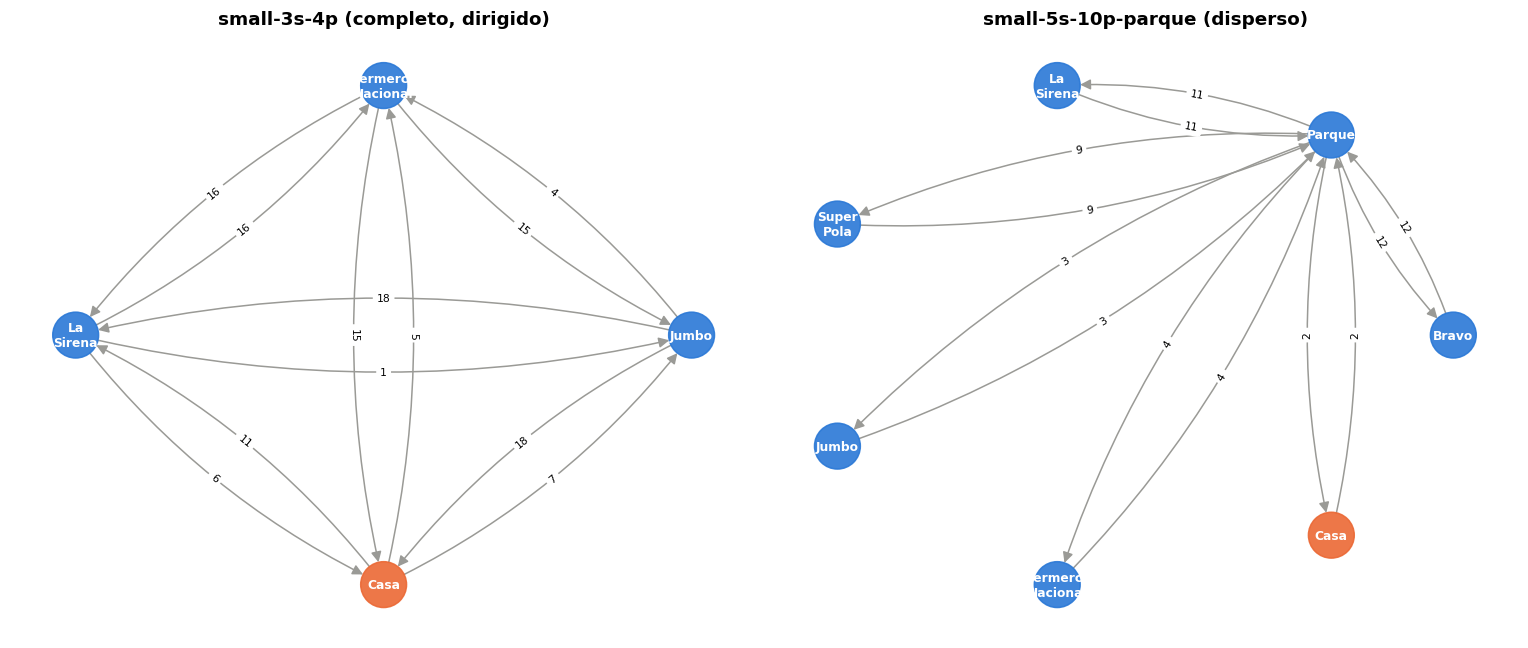

In [5]:
def draw_graph(graph, ax, title, highlight=None):
    G = nx.DiGraph()
    for a, b, d in graph.itertuples(index=False):
        if a != b:
            G.add_edge(a, b, weight=d)
    pos = nx.circular_layout(G)
    colors = [PALETTE[1] if n == "Casa" else PALETTE[0] for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=900, alpha=0.9)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white", font_weight="bold",
                            labels={n: n.replace(" ", "\n") for n in G.nodes})
    edge_colors = [PALETTE[7] if highlight and (u, v) in highlight else "#9a9a96" for u, v in G.edges]
    widths = [3 if highlight and (u, v) in highlight else 1 for u, v in G.edges]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=widths, arrowsize=14,
                           connectionstyle="arc3,rad=0.12", node_size=900)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=7, connectionstyle="arc3,rad=0.12",
                                 edge_labels={(u, v): int(d["weight"]) for u, v, d in G.edges(data=True)})
    ax.set_title(title)
    ax.axis("off")


PARQUE = DATA_DIR / "in" / "small-5s-10p-f0_10-q1_10-parque_catalog.xlsx"
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_graph(graph_df, axes[0], "small-3s-4p (completo, dirigido)")
draw_graph(load_catalog(PARQUE)[1], axes[1], "small-5s-10p-parque (disperso)")
plt.tight_layout()
save_fig(fig, "graphs")
plt.show()

El catálogo **`parque`** tiene un nodo **`Parque`** que no es una tienda, y el grafo no está completo:
para ir de una tienda a otra hay que pasar por nodos intermedios. Por eso más adelante lo convertimos
en un grafo **totalmente conectado** con Floyd-Warshall.

### 2.3 Tamaño de cada catálogo

In [6]:
rows = []
for path in sorted((DATA_DIR / "in").glob("*.xlsx")):
    cat, gr = load_catalog(path)
    n_stores, n_products = cat["store"].nunique(), cat["product"].nunique()
    nodes = set(gr["source"]) | set(gr["target"])
    rows.append({
        "catalog": path.stem.replace("_catalog", ""),
        "tiendas": n_stores, "productos": n_products,
        "filas_catálogo": len(cat),
        "densidad_%": 100 * len(cat) / (n_stores * n_products),
        "nodos": len(nodes), "aristas": len(gr),
        "precio_min": cat["price"].min(),
        "precio_max": cat["price"].max(),
        "dist_max": gr["distance"].max(),
    })
catalog_sizes = pd.DataFrame(rows).set_index("catalog")
catalog_sizes

,tiendas,productos,filas_catálogo,densidad_%,nodos,aristas,precio_min,precio_max,dist_max
catalog,,,,,,,,,
big-100s-300p-f0_10-q1_20-random,100,300,25000,83.33,101,9201,100.99,"4,999.99",19
medium-20s-50p-f0_10-q1_20-random,20,50,800,80.00,21,241,104.99,"4,959.99",19
medium-30s-80p-f0_10-q1_20-random,30,80,1900,79.17,31,461,100.99,"4,995.99",19
small-3s-4p-f1_10-q1_4-random,3,4,12,100.00,4,16,"1,274.99","4,783.99",18
small-5s-10p-f0_10-q1_10-jumbocheap,5,10,40,80.00,6,31,139.99,"4,995.99",19
small-5s-10p-f0_10-q1_10-parque,5,10,40,80.00,7,12,136.99,"4,835.99",12
small-5s-10p-f0_10-q1_10-punico,5,10,21,42.00,6,31,563.99,"4,714.99",19
small-5s-10p-f0_10-q1_10-random,5,10,40,80.00,6,31,212.99,"4,926.99",18
small-5s-10p-f0_10-q1_10-same_dist,5,10,40,80.00,6,31,173.99,"4,866.99",10


💡 **Dato clave para entender los resultados:** los precios van de cientos a miles, mientras que el
costo de transporte es `combustible (0–9) × distancia (decenas)`. **El precio de los productos domina
el costo total.** Por eso la estrategia "comprar donde sea más barato" ya es muy buena, y el valor del
AG está en decidir cuándo conviene pagar un poco más para ahorrarse un viaje.

## 3. Matriz de precios
Pasamos la hoja `catalogo` (formato largo) a una **matriz tiendas × productos**. Si una tienda no vende
un producto, su precio es `∞`, así ese producto nunca se le asigna.

¿Por qué una matriz y no seguir con la tabla? Porque el AG va a consultar precios miles de veces por segundo, y con una
matriz de NumPy sumar el precio de un cromosoma entero es una sola operación vectorizada. Y usamos `∞` en vez de `NaN`
porque `min` y `argmin` lo tratan de forma natural como "la peor opción posible".

Forma: (5, 10) | celdas sin venta (∞): 29


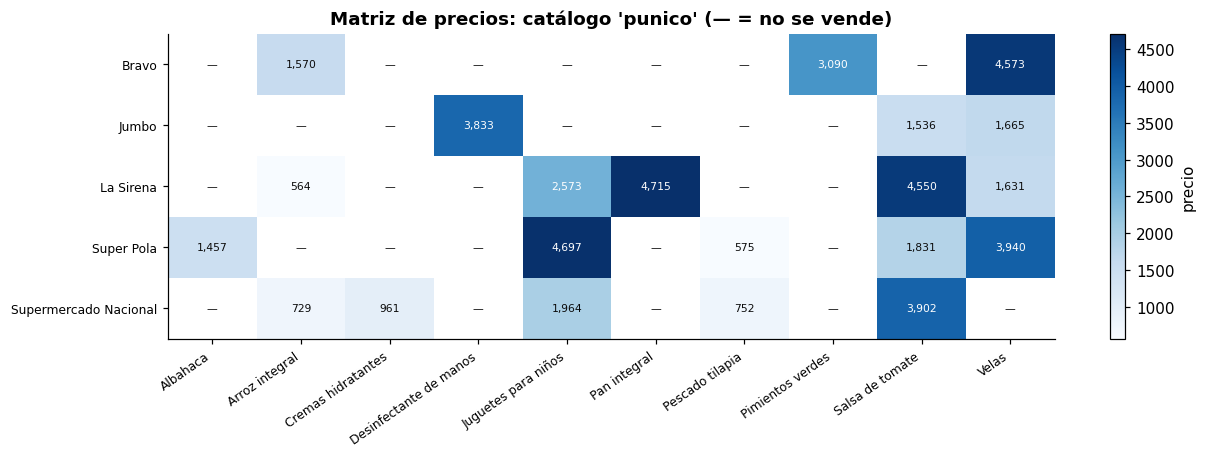

In [7]:
def build_price_matrix(catalog: pd.DataFrame) -> tuple[list[str], list[str], np.ndarray]:
    """Pivot the catalog into a stores x products matrix (np.inf = not sold)."""
    stores = sorted(catalog["store"].unique())
    products = sorted(catalog["product"].unique())
    table = catalog.pivot_table(index="store", columns="product", values="price", aggfunc="min")
    price = table.reindex(index=stores, columns=products).to_numpy(dtype=float)
    price[np.isnan(price)] = np.inf
    return stores, products, price


RANDOM5 = DATA_DIR / "in" / "small-5s-10p-f0_10-q1_10-punico_catalog.xlsx"
stores_, products_, price_ = build_price_matrix(load_catalog(RANDOM5)[0])
print("Forma:", price_.shape, "| celdas sin venta (∞):", np.isinf(price_).sum())

fig, ax = plt.subplots(figsize=(13, 3.6))
shown = np.where(np.isinf(price_), np.nan, price_)
im = ax.imshow(shown, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(products_)), products_, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(stores_)), stores_, fontsize=8)
ax.grid(False)
for i in range(shown.shape[0]):
    for j in range(shown.shape[1]):
        txt = "—" if np.isnan(shown[i, j]) else f"{shown[i, j]:,.0f}"
        dark = not np.isnan(shown[i, j]) and shown[i, j] > np.nanmean(shown)
        ax.text(j, i, txt, ha="center", va="center", fontsize=7, color="white" if dark else "#0b0b0b")
ax.set_title("Matriz de precios: catálogo 'punico' (— = no se vende)")
fig.colorbar(im, ax=ax, label="precio")
save_fig(fig, "price_matrix")
plt.show()

## 4. Del grafo a la matriz de distancias

### 4.1 Matriz de adyacencia (dirigida)
`A[i, j]` es la distancia de la arista `i → j`, o `∞` si no hay arista. La diagonal vale 0 y los
self-loops se ignoran. Si una arista aparece repetida, nos quedamos con la más corta.

La matriz es dirigida (no copiamos `A[i, j]` en `A[j, i]`) por lo que vimos en el grafo: ida y vuelta pueden medir distinto.
Más adelante, en la sección 9, comprobamos con datos que esta decisión es la correcta.

In [8]:
HOME = "Casa"


def build_adjacency(graph: pd.DataFrame, nodes: list[str], directed: bool = True) -> np.ndarray:
    """Adjacency matrix with np.inf where there is no edge.

    Self-loops are ignored (staying in the same place costs 0) and repeated
    edges keep the shortest one.
    """
    idx = {name: i for i, name in enumerate(nodes)}
    A = np.full((len(nodes), len(nodes)), np.inf)
    np.fill_diagonal(A, 0.0)
    for a, b, d in graph.itertuples(index=False):
        if a == b:
            continue
        i, j = idx[a], idx[b]
        A[i, j] = min(A[i, j], d)
        if not directed:
            A[j, i] = min(A[j, i], d)
    return A


parque_graph = load_catalog(PARQUE)[1]
parque_nodes = sorted(set(parque_graph["source"]) | set(parque_graph["target"]))
A = build_adjacency(parque_graph, parque_nodes)
print("Pares (i, j) sin conexión directa:", np.isinf(A).sum())
pd.DataFrame(A, index=parque_nodes, columns=parque_nodes)

Pares (i, j) sin conexión directa: 30


,Bravo,Casa,Jumbo,La Sirena,Parque,Super Pola,Supermercado Nacional
Bravo,0.00,inf,inf,inf,12.00,inf,inf
Casa,inf,0.00,inf,inf,2.00,inf,inf
Jumbo,inf,inf,0.00,inf,3.00,inf,inf
La Sirena,inf,inf,inf,0.00,11.00,inf,inf
Parque,12.00,2.00,3.00,11.00,0.00,9.00,4.00
Super Pola,inf,inf,inf,inf,9.00,0.00,inf
Supermercado Nacional,inf,inf,inf,inf,4.00,inf,0.00


### 4.2 Floyd-Warshall: grafo totalmente conectado
Para el AG necesitamos saber cuánto cuesta ir de cualquier tienda a cualquier otra, aunque no haya una calle directa.
Por eso convertimos el grafo en uno **totalmente conectado**, donde cada par de nodos guarda su distancia mínima.
Floyd-Warshall prueba cada nodo $k$ como intermediario:

$$D^{(k)}_{ij} = \min\left(D^{(k-1)}_{ij},\; D^{(k-1)}_{ik} + D^{(k-1)}_{kj}\right)$$

Complejidad $O(n^3)$. Con NumPy el doble ciclo sobre $(i, j)$ se vectoriza con *broadcasting*, y solo
queda el ciclo sobre $k$.

In [9]:
def floyd_warshall(A: np.ndarray) -> np.ndarray:
    """All-pairs shortest paths. Turns any connected graph into a complete one.

    D[i, j] = min(D[i, j], D[i, k] + D[k, j]) for every intermediate node k,
    vectorized over (i, j) with NumPy broadcasting.
    """
    D = A.copy()
    for k in range(len(D)):
        D = np.minimum(D, D[:, [k]] + D[[k], :])
    return D


D_parque = floyd_warshall(A)
print("Pares sin conexión después de Floyd-Warshall:", np.isinf(D_parque).sum())

# Verificación contra Dijkstra de networkx
G = nx.DiGraph()
for a, b, d in parque_graph.itertuples(index=False):
    if a != b:
        G.add_edge(a, b, weight=min(d, G[a][b]["weight"]) if G.has_edge(a, b) else d)
nx_dist = dict(nx.all_pairs_dijkstra_path_length(G))
same = all(D_parque[i, j] == nx_dist[a][b] for i, a in enumerate(parque_nodes) for j, b in enumerate(parque_nodes))
print("¿Coincide con networkx?", "✅" if same else "❌")
pd.DataFrame(D_parque, index=parque_nodes, columns=parque_nodes)

Pares sin conexión después de Floyd-Warshall: 0
¿Coincide con networkx? ✅


,Bravo,Casa,Jumbo,La Sirena,Parque,Super Pola,Supermercado Nacional
Bravo,0.00,14.00,15.00,23.00,12.00,21.00,16.00
Casa,14.00,0.00,5.00,13.00,2.00,11.00,6.00
Jumbo,15.00,5.00,0.00,14.00,3.00,12.00,7.00
La Sirena,23.00,13.00,14.00,0.00,11.00,20.00,15.00
Parque,12.00,2.00,3.00,11.00,0.00,9.00,4.00
Super Pola,21.00,11.00,12.00,20.00,9.00,0.00,13.00
Supermercado Nacional,16.00,6.00,7.00,15.00,4.00,13.00,0.00


### 4.3 La instancia completa del problema
Juntamos todo en una estructura `ShoppingInstance`. Para el AG solo importan la casa y las tiendas, así
que reducimos la matriz a esos puntos: **el punto 0 es la casa y el punto `s + 1` es la tienda `s`**.
Los nodos intermedios (como `Parque`) ya quedaron "absorbidos" en las distancias mínimas.

La reducción no es solo estética: con la numeración "punto = tienda + 1", pasar de un gen (una tienda) a una fila de la
matriz es una suma, sin diccionarios de por medio en la parte que más se repite.

In [10]:
@dataclass
class ShoppingInstance:
    """Everything the optimizer needs to know about one catalog file.

    Point indexing used by ``D``: point 0 is the home, point ``s + 1`` is store ``s``.
    """
    stores: list[str]          # store names; the index is the gene value
    products: list[str]        # every product that appears in the catalog
    price: np.ndarray          # (n_stores, n_products) price, np.inf when not sold
    nodes: list[str]           # every node of the raw graph (may include non-store nodes)
    node_dist: np.ndarray      # (n_nodes, n_nodes) shortest directed distances
    D: np.ndarray              # (n_stores + 1, n_stores + 1) distances between home and stores
    catalog: pd.DataFrame      # raw "catalogo" sheet
    graph: pd.DataFrame        # raw "grafo" sheet


def load_instance(path: str | Path, directed: bool = True) -> ShoppingInstance:
    """Load a catalog file and precompute prices and shortest-path distances."""
    catalog, graph = load_catalog(path)
    stores, products, price = build_price_matrix(catalog)
    nodes = sorted(set(graph["source"]) | set(graph["target"]) | set(stores) | {HOME})
    node_dist = floyd_warshall(build_adjacency(graph, nodes, directed))
    points = [nodes.index(HOME)] + [nodes.index(s) for s in stores]
    D = node_dist[np.ix_(points, points)]
    return ShoppingInstance(stores, products, price, nodes, node_dist, D, catalog, graph)


inst_small = load_instance(SMALL)
print("Tiendas:", inst_small.stores)
print("Productos:", inst_small.products)
labels = [HOME] + inst_small.stores
pd.DataFrame(inst_small.D, index=labels, columns=labels)

Tiendas: ['Jumbo', 'La Sirena', 'Supermercado Nacional']
Productos: ['Aceite de girasol', 'Alfombras', 'Pasta de dientes', 'Purificadores de aire']


,Casa,Jumbo,La Sirena,Supermercado Nacional
Casa,0.00,7.00,11.00,5.00
Jumbo,18.00,0.00,18.00,4.00
La Sirena,6.00,1.00,0.00,5.00
Supermercado Nacional,15.00,15.00,16.00,0.00


**Detalle oculto en los datos:** algunos grafos tienen aristas de distancia **0**. Después de Floyd-Warshall, un
cero puede "propagarse" y dejar muchos pares de tiendas a distancia 0. Medimos qué fracción de pares queda así en
cada catálogo:

In [11]:
zero_rows = []
for path in sorted((DATA_DIR / "in").glob("*.xlsx")):
    inst = load_instance(path)
    n = len(inst.D)
    zero_rows.append({"catalog": path.stem.replace("_catalog", ""),
                      "aristas con distancia 0": int((inst.graph["distance"] == 0).sum()),
                      "% pares a distancia 0 (Floyd)": 100 * ((inst.D == 0).sum() - n) / (n * n - n)})
pd.DataFrame(zero_rows).set_index("catalog")

,aristas con distancia 0,% pares a distancia 0 (Floyd)
catalog,,
big-100s-300p-f0_10-q1_20-random,457,97.03
medium-20s-50p-f0_10-q1_20-random,8,3.10
medium-30s-80p-f0_10-q1_20-random,25,4.30
small-3s-4p-f1_10-q1_4-random,0,0.00
small-5s-10p-f0_10-q1_10-jumbocheap,1,3.33
small-5s-10p-f0_10-q1_10-parque,0,0.00
small-5s-10p-f0_10-q1_10-punico,1,3.33
small-5s-10p-f0_10-q1_10-random,1,3.33
small-5s-10p-f0_10-q1_10-same_dist,0,0.00


⚠️ En el catálogo **`big`** (100 tiendas) el **97 %** de los pares queda a distancia 0: ahí moverse entre tiendas es
prácticamente gratis, así que el problema se reduce a "comprar cada producto donde sea más barato". Hay que tenerlo
en cuenta al leer los resultados de ese cluster.

## 5. Formulación matemática

**Datos**
- $Q = \{1, \dots, k\}$: productos de la lista de compras.
- $S$: tiendas, y $A_i \subseteq S$: tiendas que venden el producto $i$.
- $c_{s,i}$: precio del producto $i$ en la tienda $s$.
- $d(u, v)$: distancia mínima dirigida (Floyd-Warshall), con $0$ = casa.
- $\varphi$: precio del combustible por unidad de distancia.

**Variable de decisión:** $x = (x_1, \dots, x_k)$ con $x_i \in A_i$, la tienda donde se compra el producto $i$.
Las tiendas a visitar son $U(x) = \{x_1, \dots, x_k\}$ (sin repetir).

**Objetivo**

$$\min_{x}\; f(x) = \underbrace{\sum_{i=1}^{k} c_{x_i,i}}_{\text{costo de productos}} \;+\; \varphi \cdot \underbrace{\mathrm{TSP}\big(U(x)\big)}_{\text{distancia de la ruta}}$$

$$\mathrm{TSP}(U) = \min_{\pi \in \mathrm{Perm}(U)} \Big[d(0, \pi_1) + \sum_{j=1}^{|U|-1} d(\pi_j, \pi_{j+1}) + d(\pi_{|U|}, 0)\Big]$$

Es un problema **combinatorio, no derivable** y con muchos óptimos locales, justo el tipo de problema donde
los algoritmos genéticos son útiles. El espacio de búsqueda mide $\prod_i |A_i|$ (asignaciones), y además
cada asignación tiene $|U|!$ órdenes posibles.

In [12]:
instances = {p: load_instance(p) for p in problemset["catalog_path"].unique()}


def search_space_log10(row):
    inst = instances[row.catalog_path]
    cols = [inst.products.index(p) for p in row.query]
    return np.log10(np.isfinite(inst.price[:, cols]).sum(axis=0)).sum()


problemset["log10_space"] = problemset.apply(search_space_log10, axis=1)
problemset.groupby("problem_cluster")["log10_space"].agg(["min", "median", "max"]).rename(
    columns=lambda c: f"log10(asignaciones) {c}")

,log10(asignaciones) min,log10(asignaciones) median,log10(asignaciones) max
problem_cluster,,,
big-100s-300p-f0_10-q1_20-random,1.90,16.28,30.83
medium-20s-50p-f0_10-q1_20-random,1.11,10.37,19.36
medium-30s-80p-f0_10-q1_20-random,1.36,11.62,22.47
small-3s-4p-f1_10-q1_4-random,0.48,1.19,1.91
small-5s-10p-f0_10-q1_10-jumbocheap,0.48,3.16,5.94
small-5s-10p-f0_10-q1_10-parque,0.48,3.33,5.96
small-5s-10p-f0_10-q1_10-punico,0.00,1.47,2.46
small-5s-10p-f0_10-q1_10-random,0.60,3.29,5.89
small-5s-10p-f0_10-q1_10-same_dist,0.48,3.23,5.96


Los problemas `big` llegan a $10^{31}$ asignaciones posibles (más que segundos en la edad del universo,
$\approx 4 \times 10^{17}$). Enumerarlas todas es imposible: necesitamos una **metaheurística**.

## 6. Sintaxis de los genes

| Concepto AG | En este problema |
|---|---|
| **Gen** | entero = índice de la tienda donde compro *un* producto |
| **Cromosoma** (genotipo) | vector de `k` enteros, uno por producto de la lista |
| **Alelos válidos del gen `i`** | solo las tiendas que venden el producto `i` ($A_i$) |
| **Fenotipo** | la ruta: tiendas en orden de visita + qué comprar en cada una |

**¿Por qué no incluir el orden de la ruta en el cromosoma?** Porque, fijado *qué* tiendas visitar, el mejor
orden se puede calcular de forma exacta (y rápida) con una heurística de TSP. Así el AG busca solo en el
espacio de asignaciones y **todo cromosoma es siempre válido**: no hacen falta penalizaciones ni reparaciones.

In [13]:
query_small = problemset.loc[1, "query"]
cols = [inst_small.products.index(p) for p in query_small]
allowed = [np.flatnonzero(np.isfinite(inst_small.price[:, c])) for c in cols]

example = np.array([2, 0, 0, 2])  # un cromosoma de ejemplo
pd.DataFrame({
    "gen i": range(len(query_small)),
    "producto": query_small,
    "alelos válidos": [[inst_small.stores[s] for s in a] for a in allowed],
    "valor del gen": example,
    "tienda": [inst_small.stores[s] for s in example],
    "precio": [inst_small.price[s, c] for s, c in zip(example, cols)],
})

,gen i,producto,alelos válidos,valor del gen,tienda,precio
0,0,Purificadores de aire,"[Jumbo, La Sirena, Supermercado Nacional]",2,Supermercado Nacional,"4,381.99"
1,1,Aceite de girasol,"[Jumbo, La Sirena, Supermercado Nacional]",0,Jumbo,"2,689.99"
2,2,Pasta de dientes,"[Jumbo, La Sirena, Supermercado Nacional]",0,Jumbo,"2,897.99"
3,3,Alfombras,"[Jumbo, La Sirena, Supermercado Nacional]",2,Supermercado Nacional,"1,274.99"


## 7. Heurística de ruta: ¿en qué orden visito las tiendas?
Dado el conjunto de tiendas del cromosoma, buscamos el recorrido cerrado más corto
`Casa → … → Casa`. Es un **TSP asimétrico** (el grafo es dirigido).

### 7.1 Longitud de una ruta

In [14]:
def route_length(order: list[int], D: np.ndarray) -> float:
    """Length of the closed route 0 -> order[0] -> ... -> order[-1] -> 0."""
    path = [0, *order, 0]
    return float(D[path[:-1], path[1:]].sum())


order = [3, 1]  # puntos: 3 = Supermercado Nacional, 1 = Jumbo
print("Casa → Supermercado Nacional → Jumbo → Casa =", route_length(order, inst_small.D))
print("Casa → Jumbo → Supermercado Nacional → Casa =", route_length(order[::-1], inst_small.D))

Casa → Supermercado Nacional → Jumbo → Casa = 38.0
Casa → Jumbo → Supermercado Nacional → Casa = 26.0


El orden importa: el mismo par de tiendas cuesta 38 o 26 según el sentido.

### 7.2 Held-Karp: TSP exacto por programación dinámica
`dp[mask, j]` = camino más corto que sale de casa, visita exactamente los puntos de `mask` y termina en `j`:

$$dp[mask \cup \{j\}, j] = \min_{k \in mask} \big(dp[mask, k] + d(k, j)\big)$$

Su costo es $O(2^n n^2)$, perfecto para $n \le 9$ tiendas distintas (lo usual en estas rutas).

In [15]:
def held_karp(points: list[int], D: np.ndarray) -> tuple[float, list[int]]:
    """Exact TSP by dynamic programming over subsets: O(2^n * n^2).

    dp[mask, j] = shortest path that leaves home, visits exactly the points in
    ``mask`` and ends at point j.
    """
    n = len(points)
    if n == 0:
        return 0.0, []
    sub = D[np.ix_(points, points)]
    full = 1 << n
    dp = np.full((full, n), np.inf)
    parent = np.full((full, n), -1, dtype=int)
    for j in range(n):
        dp[1 << j, j] = D[0, points[j]]
    bits = 1 << np.arange(n)
    for mask in range(1, full):
        cand = dp[mask][:, None] + sub              # cand[k, j]: arrive at j coming from k
        best_k = cand.argmin(axis=0)
        best = cand[best_k, np.arange(n)]
        free = np.flatnonzero((mask & bits) == 0)   # points not visited yet
        new_masks = mask | bits[free]
        better = best[free] < dp[new_masks, free]
        dp[new_masks[better], free[better]] = best[free[better]]
        parent[new_masks[better], free[better]] = best_k[free[better]]
    totals = dp[full - 1] + D[points, 0]
    last = int(totals.argmin())
    order, mask = [], full - 1
    while last != -1:
        order.append(points[last])
        prev = parent[mask, last]
        mask ^= 1 << last
        last = prev
    return float(totals.min()), order[::-1]


length, best_order = held_karp([1, 2, 3], inst_small.D)
print(f"Ruta óptima visitando las 3 tiendas: "
      f"Casa → {' → '.join(labels[p] for p in best_order)} → Casa = {length}")

Ruta óptima visitando las 3 tiendas: Casa → La Sirena → Jumbo → Supermercado Nacional → Casa = 31.0


### 7.3 Vecino más cercano + 2-opt (para rutas largas)
Con más de 9 tiendas, Held-Karp se vuelve caro. Ahí usamos una heurística constructiva (ir siempre a la
tienda más cercana) seguida de una búsqueda local **2-opt** (invertir segmentos mientras mejore).

In [16]:
def nearest_neighbor(points: list[int], D: np.ndarray) -> list[int]:
    """Greedy route: always go to the closest point not visited yet."""
    pending, order, current = set(points), [], 0
    while pending:
        current = min(pending, key=lambda p: D[current, p])
        order.append(current)
        pending.remove(current)
    return order


def two_opt(order: list[int], D: np.ndarray) -> list[int]:
    """Local search: reverse segments while the route gets shorter."""
    best, best_len = list(order), route_length(order, D)
    improved = True
    while improved:
        improved = False
        for i in range(len(best) - 1):
            for j in range(i + 1, len(best)):
                candidate = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                length = route_length(candidate, D)
                if length < best_len - 1e-9:
                    best, best_len, improved = candidate, length, True
    return best


inst_m30 = load_instance(DATA_DIR / "in" / "medium-30s-80p-f0_10-q1_20-random_catalog.xlsx")
points = list(range(1, 13))  # 12 tiendas
t = time.perf_counter(); nn = nearest_neighbor(points, inst_m30.D); t_nn = time.perf_counter() - t
t = time.perf_counter(); opt = two_opt(nn, inst_m30.D); t_2opt = time.perf_counter() - t
t = time.perf_counter(); hk_len, _ = held_karp(points, inst_m30.D); t_hk = time.perf_counter() - t
pd.DataFrame({
    "método": ["Vecino más cercano", "NN + 2-opt", "Held-Karp (exacto)"],
    "longitud": [route_length(nn, inst_m30.D), route_length(opt, inst_m30.D), hk_len],
    "ms": [1000 * t_nn, 1000 * (t_nn + t_2opt), 1000 * t_hk],
})

,método,longitud,ms
0,Vecino más cercano,33.00,0.05
1,NN + 2-opt,33.00,0.31
2,Held-Karp (exacto),26.00,43.42


### 7.4 `RouteSolver`: selector de método + memoización
Durante la evolución, muchos cromosomas comparten el mismo **conjunto** de tiendas. Guardamos cada ruta
resuelta en un diccionario indexado por `frozenset`, así cada conjunto se calcula una sola vez.

In [17]:
class RouteSolver:
    """Finds the visiting order for a set of stores, with memoization.

    Uses Held-Karp (exact) up to ``exact_limit`` stores and nearest neighbor +
    2-opt above that. Stores are given as store indices; point = store + 1.
    """

    def __init__(self, D: np.ndarray, exact_limit: int = 9):
        self.D = D
        self.exact_limit = exact_limit
        self.cache: dict[frozenset, tuple[float, list[int]]] = {}
        self.hits = 0
        self.misses = 0

    def solve(self, stores: Iterable[int]) -> tuple[float, list[int]]:
        key = frozenset(int(s) for s in stores)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        points = sorted(s + 1 for s in key)
        if len(points) <= self.exact_limit:
            length, order = held_karp(points, self.D)
        else:
            order = two_opt(nearest_neighbor(points, self.D), self.D)
            length = route_length(order, self.D)
        result = (length, [p - 1 for p in order])
        self.cache[key] = result
        return result


solver = RouteSolver(inst_small.D)
for stores in [[0, 2], [2, 0], [2, 0, 0, 2], [0, 1, 2]]:
    length, order = solver.solve(stores)
    print(f"{str(stores):14s} → {[inst_small.stores[s] for s in order]} = {length}")
print(f"cache: hits={solver.hits}, misses={solver.misses}")

[0, 2]         → ['Jumbo', 'Supermercado Nacional'] = 26.0
[2, 0]         → ['Jumbo', 'Supermercado Nacional'] = 26.0
[2, 0, 0, 2]   → ['Jumbo', 'Supermercado Nacional'] = 26.0
[0, 1, 2]      → ['La Sirena', 'Jumbo', 'Supermercado Nacional'] = 31.0
cache: hits=2, misses=2


## 8. Función de fitness
`ShoppingProblem` une una instancia con una consulta concreta (lista + combustible). Calcula:
- `product_cost`: suma de precios, vectorizada con *fancy indexing* de NumPy.
- `transport_cost`: combustible × longitud de la ruta óptima del conjunto de tiendas.
- `cost` = la **función objetivo a minimizar**.
- `decode` / `format_answer`: convierten el genotipo en el fenotipo (la respuesta en formato `RESPUESTA> (tienda, [productos]) -> …`).

Separamos el costo en productos y transporte porque así se puede ver *de dónde* viene cada ahorro, y porque más adelante
nos sirve para entender por qué en este dataset el precio pesa mucho más que el combustible.

In [18]:
class ShoppingProblem:
    """One shopping query on one catalog.

    Gene syntax: a chromosome is an integer vector of length k (one gene per
    product in the query); gene i is the index of the store where product i is
    bought. Only stores that sell product i are allowed, so every chromosome is
    a valid purchase.
    """

    def __init__(self, instance: ShoppingInstance, query: list[str], fuel_price: float,
                 exact_limit: int = 9):
        missing = [p for p in query if p not in instance.products]
        if missing:
            raise ValueError(f"Products not found in the catalog: {missing}")
        self.instance = instance
        self.query = list(query)
        self.fuel_price = float(fuel_price)
        self.k = len(query)
        cols = [instance.products.index(p) for p in query]
        self.price = instance.price[:, cols]                       # (n_stores, k)
        self.allowed = [np.flatnonzero(np.isfinite(self.price[:, i])) for i in range(self.k)]
        if any(len(a) == 0 for a in self.allowed):
            raise ValueError("Some product is not sold by any store")
        self.router = RouteSolver(instance.D, exact_limit)
        self.evaluations = 0

    def product_cost(self, chromosome: np.ndarray) -> float:
        return float(self.price[chromosome, np.arange(self.k)].sum())

    def transport_cost(self, chromosome: np.ndarray) -> float:
        length, _ = self.router.solve(chromosome)
        return self.fuel_price * length

    def cost(self, chromosome: np.ndarray) -> float:
        """Objective to minimize."""
        self.evaluations += 1
        return self.product_cost(chromosome) + self.transport_cost(chromosome)

    def evaluate(self, population: np.ndarray) -> np.ndarray:
        """Cost of every chromosome in the population (one row per individual)."""
        return np.array([self.cost(ind) for ind in population])

    def decode(self, chromosome: np.ndarray) -> list[tuple[str, list[str]]]:
        """Phenotype: the stores in visiting order with what to buy in each one."""
        _, order = self.router.solve(chromosome)
        stores = self.instance.stores
        return [(stores[s], [self.query[i] for i in range(self.k) if chromosome[i] == s])
                for s in order]

    def format_answer(self, chromosome: np.ndarray) -> str:
        parts = []
        for store, items in self.decode(chromosome):
            parts.append(f"({store}, {items[0]})" if len(items) == 1
                         else f"({store}, [{', '.join(items)}])")
        return "RESPUESTA> " + " -> ".join(parts)


row = problemset.loc[1]
problem_small = ShoppingProblem(inst_small, row.query, row.fuel_price)
print("Cromosoma:", example)
print(f"Productos  = {problem_small.product_cost(example):,.2f}")
print(f"Transporte = {problem_small.transport_cost(example):,.2f}")
print(f"Total      = {problem_small.cost(example):,.2f}")
print(problem_small.format_answer(example))

Cromosoma: [2 0 0 2]
Productos  = 11,244.96
Transporte = 26.00
Total      = 11,270.96
RESPUESTA> (Jumbo, [Aceite de girasol, Pasta de dientes]) -> (Supermercado Nacional, [Purificadores de aire, Alfombras])


## 9. Validación del modelo de costo contra 504 soluciones de referencia
Antes de optimizar hay que estar **seguros de que medimos el costo igual que las referencias**. El dataset
trae 4 soluciones por problema, como secuencias `(tienda, producto)` en orden de visita. Las parseamos y
recalculamos su costo con nuestro modelo, primero suponiendo grafo **dirigido** y luego **no dirigido**.

In [19]:
_PAIR = re.compile(r"array\(\[(['\"])(.*?)\1, (['\"])(.*?)\3\]")


def parse_solution(text) -> list[tuple[str, str]] | None:
    """Parse the reference solution strings ("[array(['Jumbo', 'Arroz'], ...) ...]")."""
    if not isinstance(text, str):
        return None
    return [(m.group(2), m.group(4)) for m in _PAIR.finditer(text)]


def evaluate_sequence(instance: ShoppingInstance, sequence: list[tuple[str, str]],
                      fuel_price: float) -> float:
    """Cost of an explicit (store, product) sequence visited in the given order.

    Used to check our cost model against the reference solutions.
    """
    s_idx = {s: i for i, s in enumerate(instance.stores)}
    p_idx = {p: i for i, p in enumerate(instance.products)}
    products = sum(instance.price[s_idx[s], p_idx[p]] for s, p in sequence)
    route = [s_idx[s] + 1 for s, _ in sequence]
    return float(products + fuel_price * route_length(route, instance.D))


undirected = {p: load_instance(p, directed=False) for p in instances}
checks = []
for _, r in problemset.iterrows():
    for alg in ["qbf", "ga", "gc", "gn"]:
        sol, value = parse_solution(r[f"{alg} best solution"]), r[f"{alg} best value"]
        if sol is None or np.isnan(value):
            continue
        checks.append({
            "dirigido": abs(evaluate_sequence(instances[r.catalog_path], sol, r.fuel_price) - value) < 1e-6,
            "no_dirigido": abs(evaluate_sequence(undirected[r.catalog_path], sol, r.fuel_price) - value) < 1e-6,
        })
checks = pd.DataFrame(checks)
print(f"Soluciones verificadas: {len(checks)}")
for col in checks:
    print(f"  {col:12s}: {checks[col].sum():3d} / {len(checks)}  {'✅' if checks[col].all() else '❌'}")

Soluciones verificadas: 504
  dirigido    : 504 / 504  ✅
  no_dirigido : 224 / 504  ❌


✅ **El modelo reproduce al centavo las 504 soluciones de referencia** con grafo dirigido, rutas cerradas
y Floyd-Warshall. Con grafo no dirigido no cuadra, lo que confirma que las calles tienen sentido.
Esta celda es la base de confianza de todo lo que sigue, y también está automatizada en `tests/test_fitness.py`.

## 10. Demostración matemática paso a paso: una generación "a mano"
Tomamos el problema 1 (3 tiendas, 4 productos, combustible = 1) y una población de **4 individuos**.
Hacemos una generación completa mostrando cada número.

La idea es quitarle la "magia" al algoritmo: con 4 individuos se puede seguir cada sorteo y cada cuenta con lápiz y papel,
y queda claro que el AG no es más que repetir estos pasos muchas veces.

### 10.1 Inicialización y evaluación

In [20]:
rng_demo = np.random.default_rng(7)
P = problem_small
pop0 = np.array([[rng_demo.choice(a) for a in P.allowed] for _ in range(4)])


def explain(population, problem):
    rows = []
    for idx, ind in enumerate(population):
        length, order = problem.router.solve(ind)
        rows.append({
            "individuo": f"x{idx}", "genes": ind.tolist(),
            "ruta": " → ".join(["Casa", *[problem.instance.stores[s] for s in order], "Casa"]),
            "Σ precios": problem.product_cost(ind), "distancia": length,
            "φ·dist": problem.fuel_price * length, "f(x)": problem.product_cost(ind) + problem.fuel_price * length,
        })
    return pd.DataFrame(rows)


print("Productos:", P.query, "| φ =", P.fuel_price)
table0 = explain(pop0, P)
table0

Productos: ['Purificadores de aire', 'Aceite de girasol', 'Pasta de dientes', 'Alfombras'] | φ = 1.0


,individuo,genes,ruta,Σ precios,distancia,φ·dist,f(x)
0,x0,"[2, 1, 2, 2]",Casa → Supermercado Nacional → La Sirena → Casa,"12,656.96",27.00,27.00,"12,683.96"
1,x1,"[1, 2, 2, 0]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"13,923.96",31.00,31.00,"13,954.96"
2,x2,"[0, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,587.96",26.00,26.00,"11,613.96"
3,x3,"[2, 0, 1, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,522.96",31.00,31.00,"12,553.96"


### 10.2 Selección por ruleta (y por qué falla aquí)
Como minimizamos, usamos $\text{fitness}_i = 1/f(x_i)$ y la probabilidad
$p_i = \text{fitness}_i / \sum_j \text{fitness}_j$. Luego se gira la ruleta con números aleatorios
$r \sim U(0,1)$ sobre la probabilidad acumulada.

In [21]:
costs0 = table0["f(x)"].to_numpy()
fit = 1 / costs0
roulette = pd.DataFrame({"f(x)": costs0, "1/f(x)": fit, "p_i": fit / fit.sum(),
                         "acumulada": np.cumsum(fit / fit.sum())},
                        index=table0.iloc[:, 0])
display(roulette.style.format({"f(x)": "{:,.2f}", "1/f(x)": "{:.3e}", "p_i": "{:.4f}", "acumulada": "{:.4f}"}))

r = rng_demo.random(4)
picked = np.searchsorted(np.cumsum(fit / fit.sum()), r)
for ri, pi in zip(r, picked):
    print(f"r = {ri:.4f} → x{pi}")

,f(x),1/f(x),p_i,acumulada
individuo,,,,
x0,"12,683.96",7.884e-05,0.2493,0.2493
x1,"13,954.96",7.166e-05,0.2266,0.4759
x2,"11,613.96",8.610e-05,0.2723,0.7481
x3,"12,553.96",7.966e-05,0.2519,1.0000


r = 0.7971 → x3
r = 0.4679 → x1
r = 0.3030 → x1
r = 0.2784 → x1


Las probabilidades salen casi iguales (≈ 0.25 cada una), porque los costos difieren poco *en proporción*.
La ruleta casi no ejerce **presión selectiva**. Por eso también implementamos **torneo** y **ranking**,
que dependen del *orden* de los costos y no de su magnitud.

### 10.3 Selección por torneo (k = 2)
Se toman `k` individuos al azar y gana el de menor costo.

In [22]:
parents = []
for _ in range(4):
    a, b = rng_demo.integers(0, 4, size=2)
    winner = a if costs0[a] <= costs0[b] else b
    parents.append(winner)
    print(f"torneo x{a} ({costs0[a]:,.2f}) vs x{b} ({costs0[b]:,.2f}) → gana x{winner}")

torneo x2 (11,613.96) vs x1 (13,954.96) → gana x2
torneo x3 (12,553.96) vs x1 (13,954.96) → gana x3
torneo x1 (13,954.96) vs x2 (11,613.96) → gana x2
torneo x2 (11,613.96) vs x2 (11,613.96) → gana x2


### 10.4 Cruce de un punto
Se elige un punto de corte `c` y los hijos intercambian las colas: `h1 = p1[:c] + p2[c:]`.

In [23]:
children = []
for a, b in [(parents[0], parents[1]), (parents[2], parents[3])]:
    p1, p2 = pop0[a], pop0[b]
    cut = rng_demo.integers(1, P.k)
    h1, h2 = np.concatenate([p1[:cut], p2[cut:]]), np.concatenate([p2[:cut], p1[cut:]])
    print(f"p1=x{a} {p1.tolist()}  p2=x{b} {p2.tolist()}  corte/cut={cut}  →  h1={h1.tolist()}  h2={h2.tolist()}")
    children += [h1, h2]

p1=x2 [0, 0, 0, 2]  p2=x3 [2, 0, 1, 2]  corte/cut=2  →  h1=[0, 0, 1, 2]  h2=[2, 0, 0, 2]
p1=x2 [0, 0, 0, 2]  p2=x2 [0, 0, 0, 2]  corte/cut=3  →  h1=[0, 0, 0, 2]  h2=[0, 0, 0, 2]


### 10.5 Mutación por reinicio aleatorio ($p_m = 1/k = 0.25$)
Por cada gen se sortea $r \sim U(0,1)$. Si $r < p_m$, el gen toma otra tienda válida al azar.

In [24]:
pm = 1 / P.k
mutated = []
for child in children:
    new = child.copy()
    draws = rng_demo.random(P.k)
    for i in np.flatnonzero(draws < pm):
        new[i] = rng_demo.choice(P.allowed[i])
    print(f"{child.tolist()}  r={np.round(draws, 2).tolist()}  →  {new.tolist()}")
    mutated.append(new)
mutated = np.array(mutated)

[0, 0, 1, 2]  r=[0.79, 0.62, 0.99, 0.22]  →  [0, 0, 1, 2]
[2, 0, 0, 2]  r=[0.61, 0.04, 0.04, 0.51]  →  [2, 0, 2, 2]
[0, 0, 0, 2]  r=[0.92, 0.63, 0.51, 0.5]  →  [0, 0, 0, 2]
[0, 0, 0, 2]  r=[0.25, 0.01, 0.19, 0.69]  →  [1, 2, 0, 2]


### 10.6 Reemplazo con elitismo (1 élite)
El mejor padre pasa intacto y los 3 mejores hijos completan la nueva población.

In [25]:
child_costs = P.evaluate(mutated)
elite = costs0.argmin()
keep = child_costs.argsort()[:3]
pop1 = np.vstack([pop0[elite], mutated[keep]])
table1 = explain(pop1, P)
display(table1)
print(f"Mejor costo  gen 0 = {costs0.min():,.2f}  →  gen 1 = {table1['f(x)'].min():,.2f}")
print(f"Costo promedio gen 0 = {costs0.mean():,.2f}  →  gen 1 = {table1['f(x)'].mean():,.2f}")
print(f"Óptimo de referencia (qbf) = {row['qbf best value']:,.2f}")

,individuo,genes,ruta,Σ precios,distancia,φ·dist,f(x)
0,x0,"[0, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,587.96",26.00,26.00,"11,613.96"
1,x1,"[2, 0, 2, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,370.96",26.00,26.00,"11,396.96"
2,x2,"[0, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,587.96",26.00,26.00,"11,613.96"
3,x3,"[0, 0, 1, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,865.96",31.00,31.00,"12,896.96"


Mejor costo  gen 0 = 11,613.96  →  gen 1 = 11,396.96
Costo promedio gen 0 = 12,701.71  →  gen 1 = 11,880.46
Óptimo de referencia (qbf) = 11,270.96


Repetir este ciclo (selección → cruce → mutación → reemplazo) es todo lo que hace un AG. A continuación
implementamos cada paso como una función reutilizable y parametrizada.

## 11. Operadores genéticos

### 11.1 Inicialización
- **Aleatoria:** cada gen toma una tienda válida al azar, lo que da diversidad máxima.
- **Sembrada (seeding):** además se incluyen soluciones heurísticas conocidas. Usamos dos *greedy*, que también
  sirven como baselines: **el más barato** (ignora distancias) y **el más cercano** (ignora precios).

Agregamos el seeding porque arrancar solo con individuos aleatorios desperdicia las primeras generaciones redescubriendo
algo obvio, como "compra donde es más barato". Con las semillas el AG parte de soluciones razonables y nunca termina peor
que ellas. En la sección 15 lo comparamos con y sin seeding para ver cuánto aporta de verdad.

In [26]:
def greedy_cheapest(problem: ShoppingProblem) -> np.ndarray:
    """Buy every product where it is cheapest, ignoring distances."""
    return problem.price.argmin(axis=0)


def greedy_nearest(problem: ShoppingProblem) -> np.ndarray:
    """From the current position, go to the closest store that sells something
    still pending and buy there everything it can. Ignores prices."""
    chromosome = np.full(problem.k, -1)
    D, current = problem.instance.D, 0
    while (pending := np.flatnonzero(chromosome < 0)).size:
        candidates = {s for i in pending for s in problem.allowed[i]}
        store = min(candidates, key=lambda s: D[current, s + 1])
        for i in pending:
            if np.isfinite(problem.price[store, i]):
                chromosome[i] = store
        current = store + 1
    return chromosome


def init_random(problem: ShoppingProblem, pop_size: int, rng: np.random.Generator) -> np.ndarray:
    """Each gene takes a random store among the ones that sell that product."""
    return np.array([[rng.choice(a) for a in problem.allowed] for _ in range(pop_size)])


def init_seeded(problem: ShoppingProblem, pop_size: int, rng: np.random.Generator,
                seeds: list[np.ndarray]) -> np.ndarray:
    """Random population that also contains some known good chromosomes (e.g. greedy)."""
    population = init_random(problem, pop_size, rng)
    for i, seed in enumerate(seeds[:pop_size]):
        population[i] = seed
    return population


rng = np.random.default_rng(SEED)
pop = init_seeded(P, 6, rng, [greedy_cheapest(P), greedy_nearest(P)])
display(explain(pop, P))

,individuo,genes,ruta,Σ precios,distancia,φ·dist,f(x)
0,x0,"[2, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,244.96",26.00,26.00,"11,270.96"
1,x1,"[2, 2, 2, 2]",Casa → Supermercado Nacional → Casa,"12,797.96",20.00,20.00,"12,817.96"
2,x2,"[0, 0, 1, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,865.96",31.00,31.00,"12,896.96"
3,x3,"[2, 2, 2, 2]",Casa → Supermercado Nacional → Casa,"12,797.96",20.00,20.00,"12,817.96"
4,x4,"[1, 0, 2, 1]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"14,191.96",31.00,31.00,"14,222.96"
5,x5,"[1, 1, 0, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,932.96",31.00,31.00,"12,963.96"


### 11.2 Selección
Comparamos la **presión selectiva** de las tres técnicas: con una población de 30 individuos de un
problema mediano, seleccionamos 100 000 veces y contamos cuántas veces sale cada individuo según su ranking.

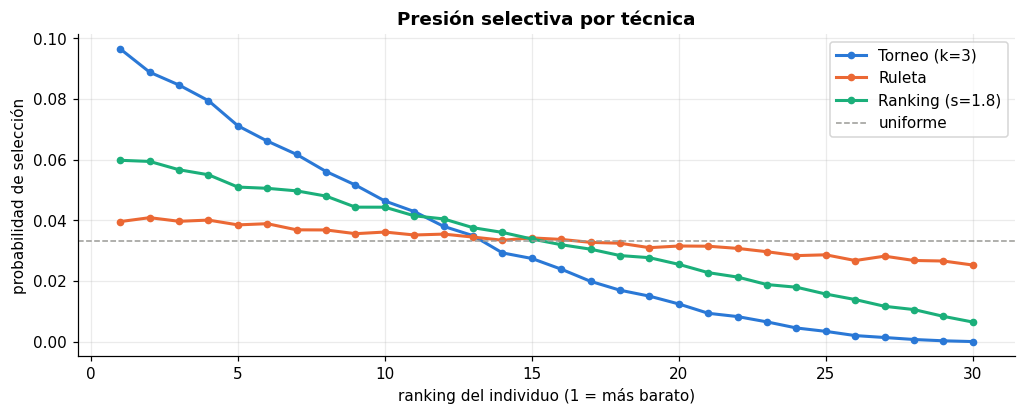

Rango de costos: 33,559 – 55,250 (el peor cuesta solo 65% más)


In [27]:
def selection_tournament(costs: np.ndarray, n: int, rng: np.random.Generator,
                         k: int = 3) -> np.ndarray:
    """Pick k individuals at random; the cheapest one wins. Repeat n times."""
    contenders = rng.integers(0, len(costs), size=(n, k))
    return contenders[np.arange(n), costs[contenders].argmin(axis=1)]


def selection_roulette(costs: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    """Fitness-proportional selection with fitness = 1 / cost."""
    fitness = 1.0 / costs
    return rng.choice(len(costs), size=n, p=fitness / fitness.sum())


def selection_rank(costs: np.ndarray, n: int, rng: np.random.Generator,
                   pressure: float = 1.8) -> np.ndarray:
    """Linear ranking: probability depends on the position, not on the cost value.

    The best gets ``pressure / N`` and the worst ``(2 - pressure) / N``.
    """
    N = len(costs)
    ranks = np.empty(N)
    ranks[costs.argsort()[::-1]] = np.arange(N)          # worst -> 0, best -> N-1
    probs = ((2 - pressure) + 2 * (pressure - 1) * ranks / max(N - 1, 1)) / N
    return rng.choice(N, size=n, p=probs / probs.sum())


r_med = problemset[problemset.problem_cluster.str.startswith("medium-30")].iloc[3]
P_med = ShoppingProblem(instances[r_med.catalog_path], r_med.query, r_med.fuel_price)
demo_costs = np.sort(P_med.evaluate(init_random(P_med, 30, rng)))
fig, ax = plt.subplots(figsize=(11, 3.8))
for name, fn in [("Torneo (k=3)", selection_tournament), ("Ruleta", selection_roulette),
                 ("Ranking (s=1.8)", selection_rank)]:
    counts = np.bincount(fn(demo_costs, 100_000, rng), minlength=30) / 100_000
    ax.plot(range(1, 31), counts, marker="o", markersize=4, label=name)
ax.axhline(1 / 30, color="#9a9a96", ls="--", lw=1, label="uniforme")
ax.set_xlabel("ranking del individuo (1 = más barato)")
ax.set_ylabel("probabilidad de selección")
ax.set_title("Presión selectiva por técnica")
ax.legend()
save_fig(fig, "selection_pressure")
plt.show()
print(f"Rango de costos: {demo_costs.min():,.0f} – {demo_costs.max():,.0f} "
      f"(el peor cuesta solo {100 * (demo_costs.max() / demo_costs.min() - 1):.0f}% más)")

### 11.3 Cruce (crossover)
Los tres operadores trabajan **posición por posición**, así que el hijo hereda en el gen `i` una tienda que ya
era válida para el producto `i`: **los hijos son siempre válidos**.

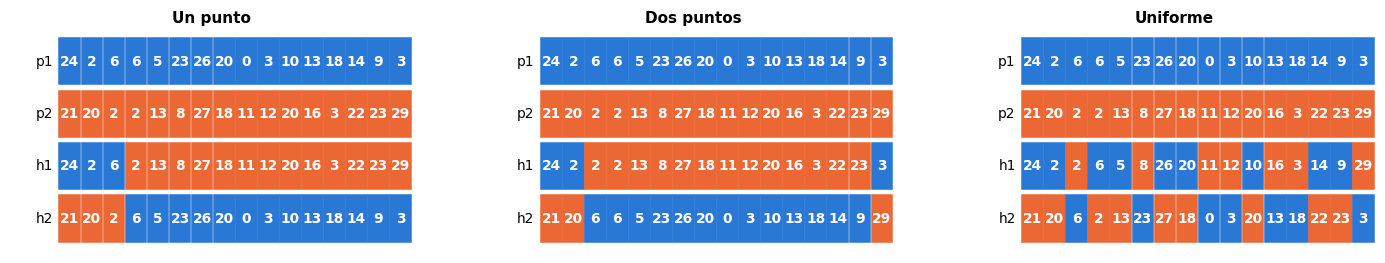

In [28]:
def crossover_one_point(p1: np.ndarray, p2: np.ndarray, rng: np.random.Generator):
    """Cut both parents at the same random point and swap the tails."""
    if len(p1) < 2:
        return p1.copy(), p2.copy()
    cut = rng.integers(1, len(p1))
    return (np.concatenate([p1[:cut], p2[cut:]]),
            np.concatenate([p2[:cut], p1[cut:]]))


def crossover_two_point(p1: np.ndarray, p2: np.ndarray, rng: np.random.Generator):
    """Swap the middle segment between two random cut points."""
    if len(p1) < 3:
        return crossover_one_point(p1, p2, rng)
    a, b = sorted(rng.choice(np.arange(1, len(p1)), size=2, replace=False))
    c1, c2 = p1.copy(), p2.copy()
    c1[a:b], c2[a:b] = p2[a:b], p1[a:b]
    return c1, c2


def crossover_uniform(p1: np.ndarray, p2: np.ndarray, rng: np.random.Generator):
    """Each gene comes from either parent with probability 0.5."""
    mask = rng.random(len(p1)) < 0.5
    return np.where(mask, p1, p2), np.where(mask, p2, p1)


def plot_genes(rows, title, ax, colors):
    for r, (label, genes, row_colors) in enumerate(rows):
        for c, (g, col) in enumerate(zip(genes, row_colors)):
            ax.add_patch(plt.Rectangle((c, -r), 0.94, 0.88, color=col))
            ax.text(c + 0.47, -r + 0.44, str(g), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        ax.text(-0.3, -r + 0.44, label, ha="right", va="center", fontsize=9)
    ax.set_xlim(-2.2, len(rows[0][1])); ax.set_ylim(-len(rows) + 0.8, 1); ax.axis("off"); ax.set_title(title, fontsize=10)


p1, p2 = init_random(P_med, 2, np.random.default_rng(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 2.6))
for ax, (name, fn) in zip(axes, [("Un punto", crossover_one_point), ("Dos puntos", crossover_two_point),
                                 ("Uniforme", crossover_uniform)]):
    c1, c2 = fn(p1, p2, np.random.default_rng(11))
    src_color = lambda child: [PALETTE[0] if a == b else PALETTE[1] for a, b in zip(child, p1)]
    plot_genes([("p1", p1, [PALETTE[0]] * P_med.k), ("p2", p2, [PALETTE[1]] * P_med.k),
                ("h1", c1, src_color(c1)), ("h2", c2, src_color(c2))], name, ax, PALETTE)
save_fig(fig, "crossover")
plt.show()

Azul = gen heredado de `p1`, naranja = gen heredado de `p2` (si ambos padres coinciden en una posición, se ve azul).

### 11.4 Mutación
- **Reinicio aleatorio:** el gen salta a *cualquier* tienda válida. Explora.
- **Consolidación (heurística):** el gen se mueve a una tienda **que la ruta ya visita**. Busca rutas con menos
  paradas, es decir, explota.

La segunda la agregamos porque el reinicio aleatorio casi nunca "descubre" por sí solo que conviene juntar productos en
la misma tienda para ahorrarse un viaje. La idea era darle ese empujón. Spoiler: en el benchmark se ve que empuja
demasiado.

Medimos su efecto en el número de tiendas distintas que visita el cromosoma:

In [29]:
def mutation_random_reset(chromosome: np.ndarray, problem: ShoppingProblem,
                          rng: np.random.Generator, pm: float) -> np.ndarray:
    """With probability pm, a gene jumps to any store that sells the product."""
    child = chromosome.copy()
    for i in np.flatnonzero(rng.random(len(child)) < pm):
        child[i] = rng.choice(problem.allowed[i])
    return child


def mutation_consolidate(chromosome: np.ndarray, problem: ShoppingProblem,
                         rng: np.random.Generator, pm: float) -> np.ndarray:
    """With probability pm, move a product to a store the route already visits.

    Heuristic mutation: fewer distinct stores means a shorter trip. If no other
    visited store sells the product, it falls back to a random reset.
    """
    child = chromosome.copy()
    for i in np.flatnonzero(rng.random(len(child)) < pm):
        visited = set(np.delete(child, i).tolist())
        options = [s for s in problem.allowed[i] if s in visited and s != child[i]]
        child[i] = rng.choice(options) if options else rng.choice(problem.allowed[i])
    return child


base = init_random(P_med, 2000, np.random.default_rng(5))
summary = {"original": [len(set(c)) for c in base]}
for name, fn in [("random_reset", mutation_random_reset), ("consolidate", mutation_consolidate)]:
    summary[name] = [len(set(fn(c, P_med, rng, pm=0.3))) for c in base]
print(f"Tiendas distintas por cromosoma (k = {P_med.k} productos, pm = 0.3)")
pd.DataFrame(summary).describe().loc[["mean", "min", "max"]]

Tiendas distintas por cromosoma (k = 16 productos, pm = 0.3)


,original,random_reset,consolidate
mean,12.50,12.52,10.00
min,8.00,8.00,5.00
max,16.00,16.00,14.00


### 11.5 Reemplazo con elitismo y 11.6 condición de término
- **Elitismo:** los `n_elite` mejores padres sobreviven intactos y el resto de la población se llena con los
  mejores hijos. Así el mejor costo **nunca empeora** entre generaciones.
- **Término:** se para al llegar al máximo de generaciones **o** tras `patience` generaciones sin mejora.

In [30]:
def replacement_elitism(population: np.ndarray, costs: np.ndarray,
                        offspring: np.ndarray, offspring_costs: np.ndarray,
                        n_elite: int) -> tuple[np.ndarray, np.ndarray]:
    """Generational replacement that keeps the n_elite best parents untouched."""
    elite = costs.argsort()[:n_elite]
    keep = offspring_costs.argsort()[:len(population) - n_elite]
    return (np.vstack([population[elite], offspring[keep]]),
            np.concatenate([costs[elite], offspring_costs[keep]]))


def should_stop(generation: int, max_generations: int, stall: int, patience: int) -> bool:
    """Stop at the generation limit or after ``patience`` generations without improvement."""
    return generation >= max_generations or stall >= patience


pop_a = init_random(P_med, 6, rng); cost_a = P_med.evaluate(pop_a)
pop_b = init_random(P_med, 6, rng); cost_b = P_med.evaluate(pop_b)
new_pop, new_costs = replacement_elitism(pop_a, cost_a, pop_b, cost_b, n_elite=2)
print("Padres :", np.sort(cost_a).round(0))
print("Hijos :", np.sort(cost_b).round(0))
print("Nueva    :", new_costs.round(0), "← 2 élites + 4 mejores hijos")
print()
for g, stall in [(10, 3), (200, 0), (57, 50)]:
    print(f"should_stop(gen={g}, max=200, stall={stall}, patience=50) = {should_stop(g, 200, stall, 50)}")

Padres : [31957. 36586. 37774. 42184. 45013. 46824.]
Hijos : [30668. 37556. 38652. 41358. 41852. 42257.]
Nueva    : [31957. 36586. 30668. 37556. 38652. 41358.] ← 2 élites + 4 mejores hijos

should_stop(gen=10, max=200, stall=3, patience=50) = False
should_stop(gen=200, max=200, stall=0, patience=50) = True
should_stop(gen=57, max=200, stall=50, patience=50) = True


## 12. La clase `GeneticShoppingOptimizer`
Agrupa los pasos anteriores, **un método por paso**, y recibe todos los hiperparámetros en el constructor.
La técnica de selección, cruce y mutación se elige por nombre, así compararlas es trivial.

¿Por qué una clase y no una función gigante? Porque cada paso queda aislado y se puede cambiar o probar por separado, y
porque los benchmarks de más abajo se reducen a crear el optimizador con otros parámetros.

In [31]:
@dataclass
class GAResult:
    best_chromosome: np.ndarray
    best_cost: float
    answer: str
    generations: int
    evaluations: int
    elapsed: float
    history: pd.DataFrame = field(repr=False)


class GeneticShoppingOptimizer:
    """Genetic algorithm that minimizes product cost + fuel cost of a shopping trip.

    Hyperparameters
    ---------------
    pop_size      individuals per generation
    generations   maximum number of generations
    pc            crossover probability
    pm            per-gene mutation probability (default 1 / k)
    selection     'tournament' | 'roulette' | 'rank'
    crossover     'one_point' | 'two_point' | 'uniform'
    mutation      'random_reset' | 'consolidate'
    tournament_k  tournament size
    rank_pressure selective pressure for rank selection (1..2)
    elitism       how many of the best parents survive untouched
    patience      stop after this many generations without improvement
    seeding       put the two greedy solutions in the initial population
    seed          random seed (reproducibility)
    """

    CROSSOVERS = {"one_point": crossover_one_point, "two_point": crossover_two_point,
                  "uniform": crossover_uniform}
    MUTATIONS = {"random_reset": mutation_random_reset, "consolidate": mutation_consolidate}

    def __init__(self, problem: ShoppingProblem, pop_size: int = 80, generations: int = 200,
                 pc: float = 0.9, pm: float | None = None, selection: str = "tournament",
                 crossover: str = "uniform", mutation: str = "random_reset",
                 tournament_k: int = 3, rank_pressure: float = 1.8, elitism: int = 2,
                 patience: int = 50, seeding: bool = True, seed: int | None = None):
        self.problem = problem
        self.pop_size = pop_size
        self.generations = generations
        self.pc = pc
        self.pm = pm if pm is not None else 1.0 / problem.k
        self.selection_name, self.crossover_name, self.mutation_name = selection, crossover, mutation
        self.selections = {"tournament": partial(selection_tournament, k=tournament_k),
                           "roulette": selection_roulette,
                           "rank": partial(selection_rank, pressure=rank_pressure)}
        self.elitism = elitism
        self.patience = patience
        self.seeding = seeding
        self.rng = np.random.default_rng(seed)

    # -- one method per step -------------------------------------------------

    def initialize(self) -> np.ndarray:
        if self.seeding:
            seeds = [greedy_cheapest(self.problem), greedy_nearest(self.problem)]
            return init_seeded(self.problem, self.pop_size, self.rng, seeds)
        return init_random(self.problem, self.pop_size, self.rng)

    def evaluate(self, population: np.ndarray) -> np.ndarray:
        return self.problem.evaluate(population)

    def select(self, costs: np.ndarray, n: int) -> np.ndarray:
        return self.selections[self.selection_name](costs, n, self.rng)

    def crossover(self, p1: np.ndarray, p2: np.ndarray):
        if self.rng.random() < self.pc:
            return self.CROSSOVERS[self.crossover_name](p1, p2, self.rng)
        return p1.copy(), p2.copy()

    def mutate(self, chromosome: np.ndarray) -> np.ndarray:
        return self.MUTATIONS[self.mutation_name](chromosome, self.problem, self.rng, self.pm)

    def replace(self, population, costs, offspring, offspring_costs):
        return replacement_elitism(population, costs, offspring, offspring_costs, self.elitism)

    def should_stop(self, generation: int, stall: int) -> bool:
        return should_stop(generation, self.generations, stall, self.patience)

    # -- main loop -----------------------------------------------------------

    def run(self, verbose: bool = False) -> GAResult:
        start = time.perf_counter()
        self.problem.evaluations = 0
        population = self.initialize()
        costs = self.evaluate(population)
        best_idx = costs.argmin()
        best, best_cost = population[best_idx].copy(), costs[best_idx]
        history, generation, stall = [], 0, 0

        while True:
            history.append({"generation": generation, "best": best_cost,
                            "mean": costs.mean(), "worst": costs.max(),
                            "diversity": len(np.unique(population, axis=0)) / len(population)})
            if verbose and generation % 10 == 0:
                print(f"gen {generation:4d} | best {best_cost:12.2f} | mean {costs.mean():12.2f}")
            if self.should_stop(generation, stall):
                break

            parents = self.select(costs, self.pop_size + self.pop_size % 2)
            offspring = []
            for a, b in zip(parents[::2], parents[1::2]):
                for child in self.crossover(population[a], population[b]):
                    offspring.append(self.mutate(child))
            offspring = np.array(offspring)
            population, costs = self.replace(population, costs, offspring, self.evaluate(offspring))

            generation += 1
            if costs.min() < best_cost - 1e-9:
                best_idx = costs.argmin()
                best, best_cost, stall = population[best_idx].copy(), costs[best_idx], 0
            else:
                stall += 1

        return GAResult(best, float(best_cost), self.problem.format_answer(best), generation,
                        self.problem.evaluations, time.perf_counter() - start,
                        pd.DataFrame(history))


# Hiperparámetros y sus valores por defecto
pd.Series({name: p.default for name, p in inspect.signature(GeneticShoppingOptimizer.__init__).parameters.items()
           if p.default is not inspect.Parameter.empty}, name="default").to_frame()

,default
pop_size,80
generations,200
pc,0.90
pm,None
selection,tournament
crossover,uniform
mutation,random_reset
tournament_k,3
rank_pressure,1.80
elitism,2


## 13. Ejecución en un problema
Un problema mediano (30 tiendas) **sin seeding**, para ver al AG evolucionar desde una población aleatoria.

In [32]:
r_run = problemset[problemset.problem_cluster.str.startswith("medium-30")].iloc[7]
P_run = ShoppingProblem(instances[r_run.catalog_path], r_run.query, r_run.fuel_price)
print(f"{r_run.problem_cluster} | k = {P_run.k} productos | φ = {P_run.fuel_price}")
ga = GeneticShoppingOptimizer(P_run, pop_size=80, generations=300, seeding=False, seed=SEED)
res = ga.run(verbose=True)
print()
print(res.answer)
print(f"Costo = {res.best_cost:,.2f} | best_known = {r_run.best_known:,.2f} | "
      f"generaciones = {res.generations} | evaluaciones = {res.evaluations} | {res.elapsed:.2f} s")

medium-30s-80p-f0_10-q1_20-random | k = 16 productos | φ = 5.0
gen    0 | best     26619.84 | mean     41155.66


gen   10 | best      9151.84 | mean     14113.49


gen   20 | best      6462.84 | mean      9705.68


gen   30 | best      6136.84 | mean      8603.79
gen   40 | best      5392.84 | mean      8036.29


gen   50 | best      5098.84 | mean      7680.11


gen   60 | best      5083.84 | mean      7760.64
gen   70 | best      5083.84 | mean      7789.15


gen   80 | best      5079.84 | mean      8267.50
gen   90 | best      5079.84 | mean      7275.61


gen  100 | best      5004.84 | mean      7746.74
gen  110 | best      5004.84 | mean      7633.25


gen  120 | best      5004.84 | mean      7710.83
gen  130 | best      5004.84 | mean      7613.56


gen  140 | best      5004.84 | mean      7578.85

RESPUESTA> (Supermercado Precio Justo, Libros de cocina) -> (Supermercado Carrefour, Toallas sanitarias) -> (Supermercado La Fuente, Cremas para pañales) -> (Supermercado El Ahorrón, [Copas menstruales, Pilas AA]) -> (Supermercado Hiper Uno, Paraguas) -> (Olé, [Mostaza, Jugo de naranja]) -> (Supermercado Central, Salsa de pescado) -> (La Sirena, [Aceite de oliva, Ropa de bebé]) -> (Supermercado El Encanto, Filete de res) -> (Supermercado Mr. Food, Pepinos) -> (Supermercado Plaza Lama, Pasta espagueti) -> (Supermercado Los Hidalgos, Pistachos) -> (Supermercado Ever, Vinagre blanco)
Costo = 5,004.84 | best_known = 4,985.84 | generaciones = 149 | evaluaciones = 12000 | 3.04 s


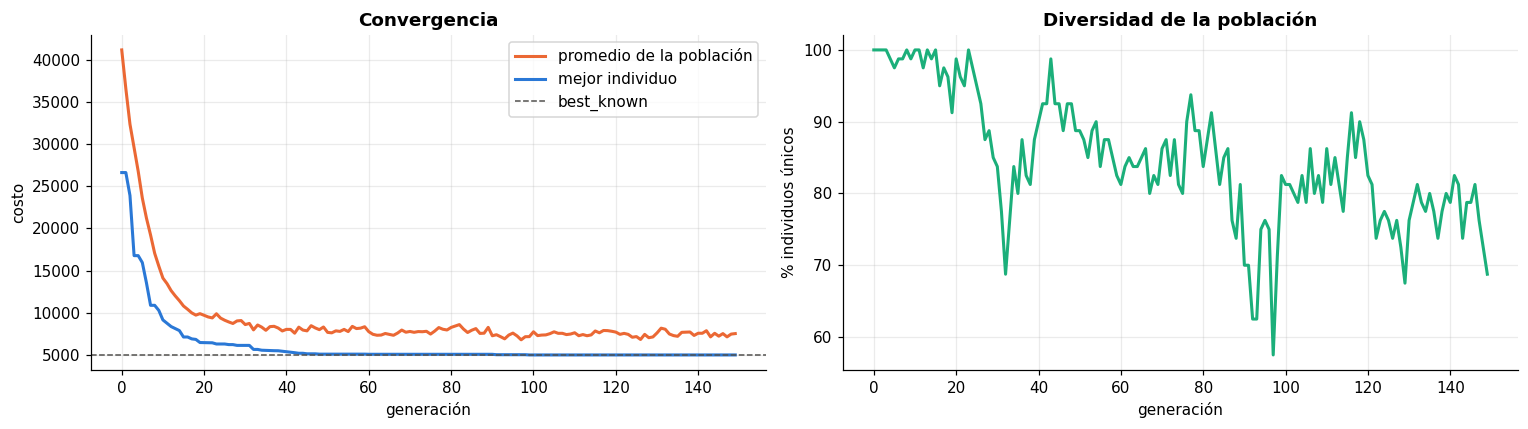

In [33]:
h = res.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h.generation, h["mean"], label="promedio de la población", color=PALETTE[1])
axes[0].plot(h.generation, h["best"], label="mejor individuo", color=PALETTE[0])
axes[0].axhline(r_run.best_known, ls="--", color="#52514e", lw=1, label="best_known")
axes[0].set_xlabel("generación"); axes[0].set_ylabel("costo")
axes[0].set_title("Convergencia"); axes[0].legend()
axes[1].plot(h.generation, 100 * h["diversity"], color=PALETTE[2])
axes[1].set_xlabel("generación"); axes[1].set_ylabel("% individuos únicos")
axes[1].set_title("Diversidad de la población")
plt.tight_layout()
save_fig(fig, "convergence")
plt.show()

### 13.1 La ruta sobre el grafo real
En el catálogo `parque` (grafo disperso), la ruta óptima entre tiendas puede pasar por nodos intermedios.
Reconstruimos el camino real para dibujarlo. Elegimos este catálogo justamente por eso: es el único donde se ve que la
"ruta" entre dos tiendas en realidad pasa por otros lugares.

RESPUESTA> (Supermercado Nacional, Sombra de ojos) -> (Super Pola, [Aceitunas negras, Cables USB, Aretes]) -> (La Sirena, Edredones) -> (Jumbo, Chupetes) -> (Bravo, [Vino tinto, Chicles de menta, Suavizante de telas, Protectores diarios])
Costo = 14,196.90 (best_known = 14,196.90, φ = 9)


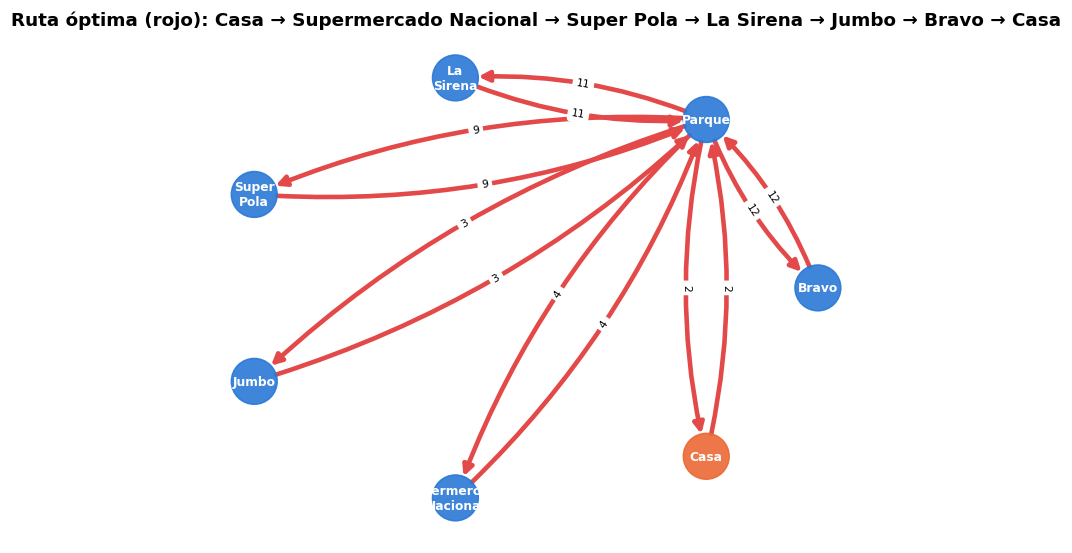

In [34]:
r_pq = problemset[problemset.problem_cluster.str.endswith("parque")].sort_values("k").iloc[-1]
P_pq = ShoppingProblem(instances[r_pq.catalog_path], r_pq.query, r_pq.fuel_price)
res_pq = GeneticShoppingOptimizer(P_pq, seed=SEED).run()
print(res_pq.answer)
print(f"Costo = {res_pq.best_cost:,.2f} (best_known = {r_pq.best_known:,.2f}, φ = {r_pq.fuel_price})")

Gp = nx.DiGraph()
for a, b, d in parque_graph.itertuples(index=False):
    if a != b:
        Gp.add_edge(a, b, weight=d)
stops = ["Casa"] + [s for s, _ in P_pq.decode(res_pq.best_chromosome)] + ["Casa"]
path_edges = set()
for a, b in zip(stops, stops[1:]):
    p = nx.shortest_path(Gp, a, b, weight="weight")
    path_edges |= set(zip(p, p[1:]))
fig, ax = plt.subplots(figsize=(8, 6))
draw_graph(parque_graph, ax, "Ruta óptima (rojo): " + " → ".join(stops), highlight=path_edges)
save_fig(fig, "route_parque")
plt.show()

## 14. Baselines y óptimo exacto
Para saber qué tan buena es una solución necesitamos el **óptimo real**. En problemas pequeños se puede calcular
enumerando **subconjuntos de tiendas** ($2^S$ en vez de $S^k$ asignaciones): para cada subconjunto se compra cada
producto donde es más barato *dentro* del subconjunto y la ruta se resuelve con Held-Karp.

Como las distancias ya son caminos mínimos, visitar menos tiendas nunca alarga la ruta, así que el mínimo sobre
todos los subconjuntos **es el óptimo global**.

In [35]:
def exact_search(problem: ShoppingProblem, max_stores: int = 14) -> tuple[np.ndarray, float]:
    """True optimum by enumerating every subset of candidate stores.

    For a fixed subset the best purchase is the cheapest store of the subset for
    each product, and the route is solved exactly. Since distances already are
    shortest paths, visiting fewer stores is never longer, so the minimum over
    all subsets is the global optimum. Cost grows as 2^S: small instances only.
    """
    candidates = sorted({int(s) for a in problem.allowed for s in a})
    if len(candidates) > max_stores:
        raise ValueError(f"{len(candidates)} candidate stores: too many for exhaustive search")
    best, best_cost = None, np.inf
    for size in range(1, len(candidates) + 1):
        for subset in combinations(candidates, size):
            sub_prices = problem.price[list(subset)]
            if not np.isfinite(sub_prices.min(axis=0)).all():
                continue
            chromosome = np.array(subset)[sub_prices.argmin(axis=0)]
            cost = problem.product_cost(chromosome) + problem.transport_cost(chromosome)
            if cost < best_cost:
                best, best_cost = chromosome, cost
    return best, float(best_cost)


small_rows = problemset[problemset.problem_cluster.str.startswith("small")]
exact_rows = []
for i, r in small_rows.iterrows():
    Pp = ShoppingProblem(instances[r.catalog_path], r.query, r.fuel_price)
    t = time.perf_counter(); _, opt_cost = exact_search(Pp); t_exact = time.perf_counter() - t
    exact_rows.append({"id": i, "cluster": "-".join(r.problem_cluster.split("-")[i] for i in (1, -1)), "exact": opt_cost,
                       "qbf": r["qbf best value"], "best_known": r.best_known, "t_exact": t_exact})
exact_df = pd.DataFrame(exact_rows).set_index("id")
print(f"Problemas pequeños: {len(exact_df)} | tiempo medio exacto: {1000 * exact_df.t_exact.mean():.1f} ms")
print(f"¿exacto ≤ best_known en todos? {(exact_df.exact <= exact_df.best_known + 1e-6).all()}")
print(f"Problemas donde el exacto MEJORA la referencia: {(exact_df.exact < exact_df.best_known - 1e-6).sum()}")
exact_df.assign(gain=exact_df.best_known - exact_df.exact).groupby("cluster").agg(
    n=("gain", "size"), mejorados=("gain", lambda g: (g > 1e-6).sum()),
    ahorro_medio=("gain", "mean"), ahorro_max=("gain", "max"))

Problemas pequeños: 100 | tiempo medio exacto: 1.1 ms
¿exacto ≤ best_known en todos? True
Problemas donde el exacto MEJORA la referencia: 12


,n,mejorados,ahorro_medio,ahorro_max
cluster,,,,
3s-random,4,0,0.00,0.00
5s-jumbocheap,16,4,30.00,180.00
5s-parque,16,0,0.00,0.00
5s-punico,16,1,7.88,126.00
5s-random,16,3,11.25,90.00
5s-same_dist,16,4,15.00,90.00
5s-same_price,16,0,0.00,0.00


La referencia "cuasi fuerza bruta" **no siempre es óptima**: nuestro método exacto encuentra soluciones más
baratas en varios problemas. Esto es importante para interpretar las métricas, porque un **error negativo**
significa que superamos a la referencia.

## 15. Validación con los 136 problemas
Corremos el AG sobre todo el dataset **en paralelo** (`joblib`, un proceso por núcleo del CPU), en dos variantes:
- **AG (seeding):** configuración por defecto, con la población inicial sembrada con los greedy.
- **AG (aleatorio):** sin seeding, el AG "puro".

Además recalculamos nuestros greedy (con ruta óptima) y los comparamos con las 4 referencias del dataset.

Corremos dos variantes del AG para ser honestos con el resultado: si solo mostráramos la versión con seeding, no se
sabría cuánto del mérito es del AG y cuánto de las heurísticas con las que arranca. Y lo paralelizamos porque cada
problema es independiente, que es el caso ideal para repartir trabajo entre núcleos.

In [36]:
def error_columns(pred: np.ndarray, true: np.ndarray) -> pd.DataFrame:
    """Per-problem errors: E (signed), AE (absolute), RE (relative)."""
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    E = pred - true
    return pd.DataFrame({"E": E, "AE": np.abs(E), "RE": E / true})


def summary_metrics(pred: np.ndarray, true: np.ndarray, tol: float = 1e-6) -> dict:
    """Aggregate metrics: ME, MAE, MSE, RMSE, MAPE, max AE, R2 and hit rate.

    hit rate = share of problems where the solver matches or beats the reference.
    """
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    ok = ~(np.isnan(pred) | np.isnan(true))
    pred, true = pred[ok], true[ok]
    E = pred - true
    ss_res, ss_tot = (E ** 2).sum(), ((true - true.mean()) ** 2).sum()
    return {
        "n": int(ok.sum()),
        "ME": E.mean(),
        "MAE": np.abs(E).mean(),
        "MSE": (E ** 2).mean(),
        "RMSE": np.sqrt((E ** 2).mean()),
        "MAPE_%": 100 * np.abs(E / true).mean(),
        "max_AE": np.abs(E).max(),
        "R2": 1 - ss_res / ss_tot if ss_tot > 0 else np.nan,
        "hit_rate_%": 100 * (E <= tol).mean(),
    }


def run_ga(instance, query, fuel, seed, **config):
    problem = ShoppingProblem(instance, query, fuel)
    result = GeneticShoppingOptimizer(problem, seed=seed, **config).run()
    return {"cost": result.best_cost, "generations": result.generations, "evaluations": result.evaluations,
            "time": result.elapsed, "answer": result.answer,
            "cache_hit_%": 100 * problem.router.hits / max(problem.router.hits + problem.router.misses, 1)}


def run_all(rows, configs, seeds=(SEED,)):
    jobs = [(i, name, s) for i in rows.index for name in configs for s in seeds]
    out = Parallel(n_jobs=N_JOBS)(
        delayed(run_ga)(instances[rows.loc[i, "catalog_path"]], rows.loc[i, "query"], rows.loc[i, "fuel_price"], s, **configs[name])
        for i, name, s in jobs)
    return pd.DataFrame([{"id": i, "config": name, "seed": s, **o} for (i, name, s), o in zip(jobs, out)])


val = cached("runs_validation", lambda: run_all(problemset, {"seeded": {"seeding": True}, "random": {"seeding": False}}))

results = problemset[["problem_cluster", "k", "fuel_price", "log10_space", "best_known", "qbf best value",
                      "ga best value", "gc best value", "gn best value"]].copy()
results["GA_seeded"] = val[val.config == "seeded"].set_index("id")["cost"]
results["GA_random"] = val[val.config == "random"].set_index("id")["cost"]
results["time_seeded"] = val[val.config == "seeded"].set_index("id")["time"]
results["generations"] = val[val.config == "seeded"].set_index("id")["generations"]
results["cache_hit_%"] = val[val.config == "seeded"].set_index("id")["cache_hit_%"]
results["exact"] = exact_df["exact"]
for i, r in problemset.iterrows():
    Pp = ShoppingProblem(instances[r.catalog_path], r.query, r.fuel_price)
    results.loc[i, "greedy_cheapest"] = Pp.cost(greedy_cheapest(Pp))
    results.loc[i, "greedy_nearest"] = Pp.cost(greedy_nearest(Pp))
results["size"] = results.problem_cluster.str.split("-").str[0]
results.to_csv(RESULTS_DIR / "validation_results.csv")
results[["problem_cluster", "k", "best_known", "exact", "GA_seeded", "GA_random", "greedy_cheapest", "greedy_nearest"]].head(10)

📂 Cargado de results/runs_validation.csv  (RECOMPUTE = True para recalcular)


,problem_cluster,k,best_known,exact,GA_seeded,GA_random,greedy_cheapest,greedy_nearest
0,small-3s-4p-f1_10-q1_4-random,1,"4,401.99","4,401.99","4,401.99","4,401.99","4,401.99","4,401.99"
1,small-3s-4p-f1_10-q1_4-random,4,"11,270.96","11,270.96","11,270.96","11,270.96","11,270.96","12,817.96"
2,small-3s-4p-f1_10-q1_4-random,1,"4,501.99","4,501.99","4,501.99","4,501.99","4,501.99","4,501.99"
3,small-3s-4p-f1_10-q1_4-random,4,"11,400.96","11,400.96","11,400.96","11,400.96","11,400.96","12,917.96"
4,small-5s-10p-f0_10-q1_10-random,1,619.99,619.99,619.99,619.99,619.99,"3,638.99"
5,small-5s-10p-f0_10-q1_10-random,4,"5,455.96","5,455.96","5,455.96","5,455.96","5,455.96","15,594.96"
6,small-5s-10p-f0_10-q1_10-random,7,"7,183.93","7,183.93","7,183.93","7,183.93","7,183.93","19,061.93"
7,small-5s-10p-f0_10-q1_10-random,10,"11,082.90","11,082.90","11,082.90","11,082.90","11,082.90","28,819.90"
8,small-5s-10p-f0_10-q1_10-random,1,"1,123.99","1,123.99","1,123.99","1,123.99","1,123.99","3,567.99"
9,small-5s-10p-f0_10-q1_10-random,4,"5,643.96","5,643.96","5,643.96","5,643.96","5,643.96","12,526.96"


### 15.1 Métricas globales (respecto a `best_known` de las referencias)
- **E** = predicho − referencia (con signo; negativo = mejor que la referencia)
- **AE** = |E| · **RE** = E / referencia · **MAE**, **MSE**, **RMSE**, **MAPE**, **R²**
- **hit rate** = % de problemas donde igualamos o superamos a la referencia

⚠️ Cuando **superamos** a la referencia, el error absoluto también crece. Por eso un MAE > 0 no siempre es malo:
hay que mirarlo junto a **ME** (con signo) y al **hit rate**.

In [37]:
solvers = {"AG (seeding) — nuestro": "GA_seeded", "AG (aleatorio) — nuestro": "GA_random",
           "Greedy barato — nuestro": "greedy_cheapest", "Greedy cercano — nuestro": "greedy_nearest",
           "ref: AG": "ga best value", "ref: cuasi fuerza bruta": "qbf best value",
           "ref: greedy barato": "gc best value", "ref: greedy cercano": "gn best value"}
global_metrics = pd.DataFrame({name: summary_metrics(results[col], results.best_known) for name, col in solvers.items()}).T
global_metrics.to_csv(RESULTS_DIR / "global_metrics.csv")
global_metrics.style.format("{:,.3f}").format({"n": "{:.0f}"}).background_gradient(subset=["MAE"], cmap="Blues")

,n,ME,MAE,MSE,RMSE,MAPE_%,max_AE,R2,hit_rate_%
AG (seeding) — nuestro,136,-16.808824,16.808824,1793.191176,42.346088,0.345250,180.000000,0.999924,100.000000
AG (aleatorio) — nuestro,136,-13.161765,18.897059,1987.617647,44.582706,0.501835,180.000000,0.999916,94.852941
Greedy barato — nuestro,136,-13.867647,17.397059,1647.367647,40.587777,0.730849,180.000000,0.999931,91.911765
Greedy cercano — nuestro,136,9368.294118,9368.294118,192825109.897059,13886.148130,353.115708,39523.000000,-7.124776,13.970588
ref: AG,133,1773.195489,1773.195489,17897149.300752,4230.502252,48.671601,20006.000000,0.044051,40.601504
ref: cuasi fuerza bruta,99,301.535354,301.535354,585282.808081,765.037782,3.383928,2727.000000,0.977421,78.787879
ref: greedy barato,136,11.323529,11.323529,1029.294118,32.082614,0.596722,180.000000,0.999957,77.941176
ref: greedy cercano,136,9607.397059,9607.397059,226367851.617647,15045.525967,352.859890,50809.000000,-8.538115,12.500000


In [38]:
by_cluster = results.groupby("problem_cluster").apply(lambda g: pd.Series({
    "n": len(g),
    "MAE AG seeding": summary_metrics(g.GA_seeded, g.best_known)["MAE"],
    "MAE AG aleatorio": summary_metrics(g.GA_random, g.best_known)["MAE"],
    "MAE ref GA": summary_metrics(g["ga best value"], g.best_known)["MAE"],
    "ME AG seeding": summary_metrics(g.GA_seeded, g.best_known)["ME"],
    "hit_% AG seeding": summary_metrics(g.GA_seeded, g.best_known)["hit_rate_%"],
    "% óptimo exacto": 100 * (abs(g.GA_seeded - g.exact) < 1e-6).mean() if g.exact.notna().all() else np.nan,
    "tiempo medio (s)": g.time_seeded.mean(),
}))
by_cluster

,n,MAE AG seeding,MAE AG aleatorio,MAE ref GA,ME AG seeding,hit_% AG seeding,% óptimo exacto,tiempo medio (s)
problem_cluster,,,,,,,,
big-100s-300p-f0_10-q1_20-random,12.00,0.00,22.67,"5,177.42",0.00,100.00,NaN,2.12
medium-20s-50p-f0_10-q1_20-random,12.00,49.25,49.25,"4,361.08",-49.25,100.00,NaN,2.87
medium-30s-80p-f0_10-q1_20-random,12.00,55.75,48.50,"5,974.75",-55.75,100.00,NaN,3.44
small-3s-4p-f1_10-q1_4-random,4.00,0.00,0.00,22.75,0.00,100.00,100.00,0.12
small-5s-10p-f0_10-q1_10-jumbocheap,16.00,30.00,30.00,"1,163.44",-30.00,100.00,100.00,0.08
small-5s-10p-f0_10-q1_10-parque,16.00,0.00,0.00,299.50,-0.00,100.00,100.00,0.08
small-5s-10p-f0_10-q1_10-punico,16.00,7.88,7.88,518.69,-7.87,100.00,100.00,0.07
small-5s-10p-f0_10-q1_10-random,16.00,11.25,11.25,647.63,-11.25,100.00,100.00,0.10
small-5s-10p-f0_10-q1_10-same_dist,16.00,15.00,15.00,547.56,-15.00,100.00,100.00,0.08


Problemas pequeños donde el AG encuentra el ÓPTIMO EXACTO: 100/100 (100.0%)
Problemas donde el AG MEJORA la mejor referencia conocida: 30/136
Ahorro total frente a best_known: 2,286.00


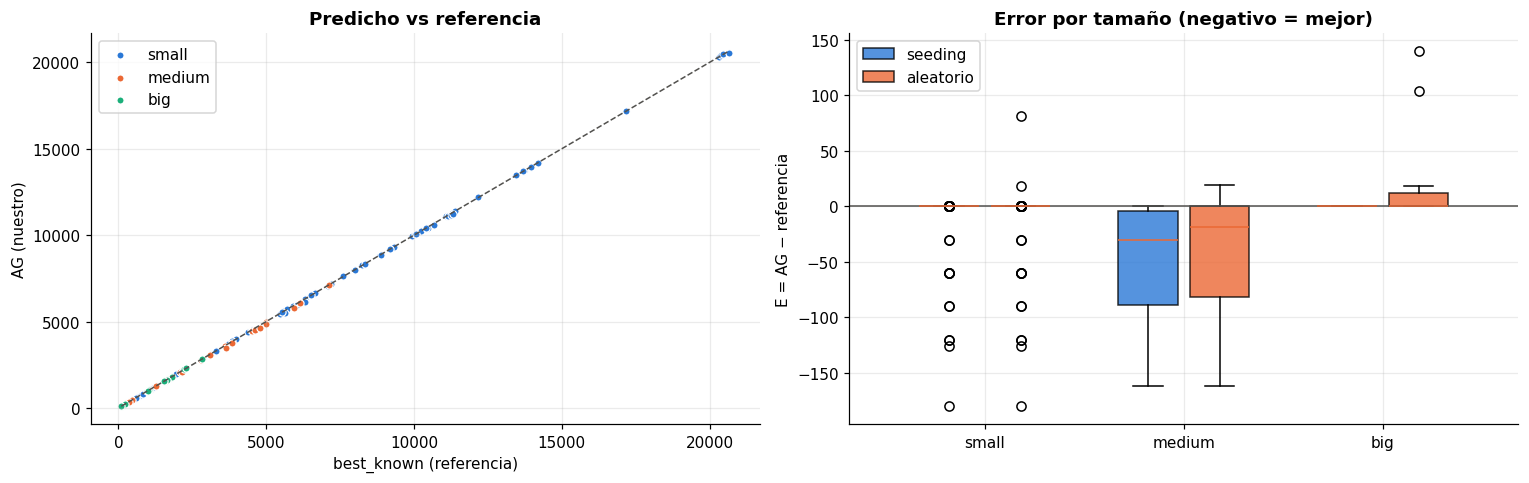

In [39]:
small_mask = results.exact.notna()
optimal = (abs(results.loc[small_mask, "GA_seeded"] - results.loc[small_mask, "exact"]) < 1e-6)
improved = (results.GA_seeded < results.best_known - 1e-6)
print(f"Problemas pequeños donde el AG encuentra el ÓPTIMO EXACTO: {optimal.sum()}/{len(optimal)} ({100 * optimal.mean():.1f}%)")
print(f"Problemas donde el AG MEJORA la mejor referencia conocida: {improved.sum()}/{len(results)}")
print(f"Ahorro total frente a best_known: {(results.best_known - results.GA_seeded).sum():,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
err = results.GA_seeded - results.best_known
for j, size in enumerate(["small", "medium", "big"]):
    m = results["size"] == size
    axes[0].scatter(results.loc[m, "best_known"], results.loc[m, "GA_seeded"], s=22, color=PALETTE[j], label=size,
                    edgecolor="white", linewidth=0.8)
lim = [results.best_known.min(), results.best_known.max()]
axes[0].plot(lim, lim, color="#52514e", lw=1, ls="--")
axes[0].set_xlabel("best_known (referencia)"); axes[0].set_ylabel("AG (nuestro)")
axes[0].set_title("Predicho vs referencia"); axes[0].legend()
data_box = [results.loc[results["size"] == s, "GA_seeded"] - results.loc[results["size"] == s, "best_known"] for s in ["small", "medium", "big"]]
data_box_r = [results.loc[results["size"] == s, "GA_random"] - results.loc[results["size"] == s, "best_known"] for s in ["small", "medium", "big"]]
pos = np.arange(3)
b1 = axes[1].boxplot(data_box, positions=pos - 0.18, widths=0.3, patch_artist=True, showfliers=True)
b2 = axes[1].boxplot(data_box_r, positions=pos + 0.18, widths=0.3, patch_artist=True, showfliers=True)
for b, c in [(b1, PALETTE[0]), (b2, PALETTE[1])]:
    for patch in b["boxes"]:
        patch.set_facecolor(c); patch.set_alpha(0.8)
axes[1].set_xticks(pos, ["small", "medium", "big"]); axes[1].axhline(0, color="#52514e", lw=1)
axes[1].set_ylabel("E = AG − referencia"); axes[1].set_title("Error por tamaño (negativo = mejor)")
axes[1].legend([b1["boxes"][0], b2["boxes"][0]], ["seeding", "aleatorio"])
plt.tight_layout()
save_fig(fig, "validation")
plt.show()

## 16. Benchmark de técnicas: 3 selecciones × 3 cruces × 2 mutaciones
Comparamos las 18 combinaciones **sin seeding** (para medir el operador, no la heurística inicial) en los 24
problemas medianos y grandes de 30 y 100 tiendas, que es donde hay diferencias, con 2 semillas cada uno.
Métrica de calidad: **RE %** = error relativo frente a `best_known`.

In [40]:
bench_rows = problemset[problemset.problem_cluster.str.startswith(("medium-30", "big"))]
configs = {f"{s}|{c}|{m}": {"selection": s, "crossover": c, "mutation": m, "seeding": False}
           for s in ["tournament", "roulette", "rank"] for c in ["one_point", "two_point", "uniform"]
           for m in ["random_reset", "consolidate"]}
bench = cached("runs_operator_benchmark", lambda: run_all(bench_rows, configs, seeds=(1, 2)))
bench[["selection", "crossover", "mutation"]] = bench.config.str.split("|", expand=True)
bench["RE_%"] = 100 * (bench.cost - problemset.loc[bench.id, "best_known"].to_numpy()) / problemset.loc[bench.id, "best_known"].to_numpy()
bench.to_csv(RESULTS_DIR / "operator_benchmark.csv", index=False)
ranking = bench.groupby(["selection", "crossover", "mutation"]).agg(
    RE_mean=("RE_%", "mean"), RE_std=("RE_%", "std"), time_s=("time", "mean"),
    generations=("generations", "mean"), evaluations=("evaluations", "mean")).sort_values("RE_mean")
ranking.style.format("{:.3f}").format({"generations": "{:.0f}", "evaluations": "{:,.0f}"}).background_gradient(subset=["RE_mean"], cmap="Blues")

📂 Cargado de results/runs_operator_benchmark.csv  (RECOMPUTE = True para recalcular)


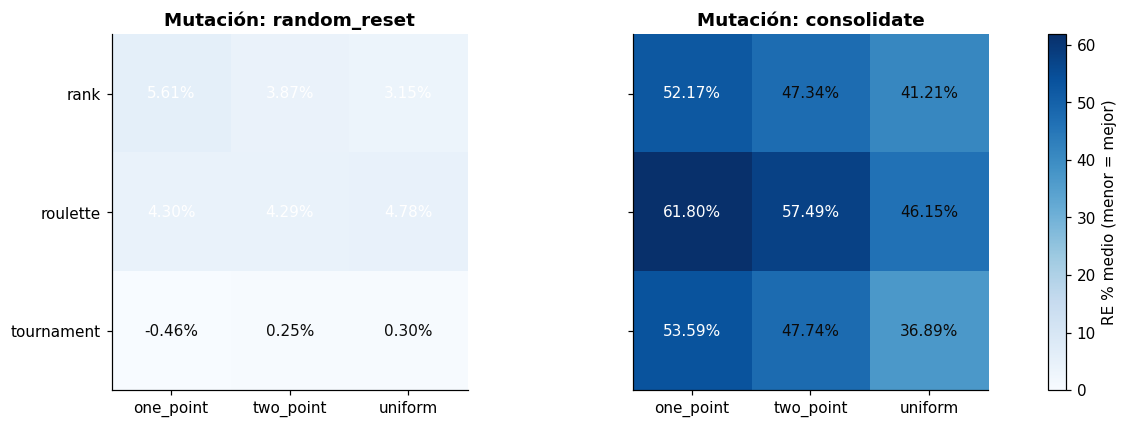

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, mut in zip(axes, ["random_reset", "consolidate"]):
    pivot = bench[bench.mutation == mut].pivot_table(index="selection", columns="crossover", values="RE_%", aggfunc="mean")
    im = ax.imshow(pivot.to_numpy(), cmap="Blues", vmin=0, vmax=bench.groupby(["selection", "crossover", "mutation"])["RE_%"].mean().max())
    ax.set_xticks(range(3), pivot.columns); ax.set_yticks(range(3), pivot.index); ax.grid(False)
    for i in range(3):
        for j in range(3):
            v = pivot.to_numpy()[i, j]
            ax.text(j, i, f"{v:.2f}%", ha="center", va="center", color="white" if v > pivot.to_numpy().mean() else "#0b0b0b")
    ax.set_title(f"Mutación: {mut}")
fig.colorbar(im, ax=axes, label="RE % medio (menor = mejor)")
save_fig(fig, "operator_heatmap")
plt.show()

**Hallazgos del benchmark:**
- **La mutación decide casi todo.** Con *reinicio aleatorio* el RE medio es ≈ 3 %, y con *consolidación* sube a ≈ 49 %.
  La consolidación junta productos en pocas tiendas demasiado rápido, la diversidad colapsa y el AG converge
  **prematuramente** (para antes: ~75 generaciones contra ~120).
- **Torneo** es la mejor selección: ≈ 0 % de RE con reinicio aleatorio, y es además la más rápida. Ruleta y ranking
  quedan en 3–6 %, coherente con la baja presión selectiva vista en la sección 11.2.
- El tipo de **cruce** pesa poco frente a los otros dos factores.

### 16.1 Memoria y tiempo por técnica
Medimos el **pico de memoria** con `tracemalloc` corriendo cada combinación sobre un problema mediano (20 tiendas)
de forma secuencial, para no mezclar procesos. `tracemalloc` hace todo más lento, así que aquí los tiempos solo
sirven para comparar entre sí.

In [42]:
r_mem = problemset[problemset.problem_cluster.str.startswith("medium-20")].sort_values("k").iloc[-1]


def memory_benchmark():
    rows = []
    for name, cfg in configs.items():
        P_b = ShoppingProblem(instances[r_mem.catalog_path], r_mem.query, r_mem.fuel_price)
        tracemalloc.start()
        res_b = GeneticShoppingOptimizer(P_b, seed=1, **cfg).run()
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        rows.append({"config": name, "peak_MB": peak / 2**20, "time_s": res_b.elapsed, "generations": res_b.generations,
                     "RE_%": 100 * (res_b.best_cost - r_mem.best_known) / r_mem.best_known})
    return pd.DataFrame(rows)


mem = cached("memory_benchmark", memory_benchmark, parallel=False).set_index("config").sort_values("RE_%")
mem

📂 Cargado de results/memory_benchmark.csv  (RECOMPUTE = True para recalcular)


,peak_MB,time_s,generations,RE_%
config,,,,
tournament|one_point|random_reset,2.62,12.89,126,-2.71
tournament|two_point|random_reset,2.57,11.88,102,-2.71
roulette|one_point|random_reset,7.19,29.66,156,-2.71
tournament|uniform|random_reset,2.93,11.12,99,-2.71
rank|uniform|random_reset,7.29,28.11,175,-2.71
rank|one_point|random_reset,6.39,23.56,155,-2.52
rank|two_point|random_reset,7.87,34.74,192,-2.12
roulette|two_point|random_reset,7.47,31.89,186,-1.23
roulette|uniform|random_reset,9.33,46.25,197,-0.76


## 17. Sensibilidad de hiperparámetros y escalabilidad
Variamos **un hiperparámetro a la vez** sobre la configuración base (torneo + uniforme + reinicio aleatorio,
sin seeding) en los mismos 24 problemas. Cambiar uno a la vez no encuentra la mejor combinación posible, pero sí deja
ver el efecto de cada parámetro por separado, que es lo que nos interesa para entenderlos.

📂 Cargado de results/runs_sensitivity.csv  (RECOMPUTE = True para recalcular)


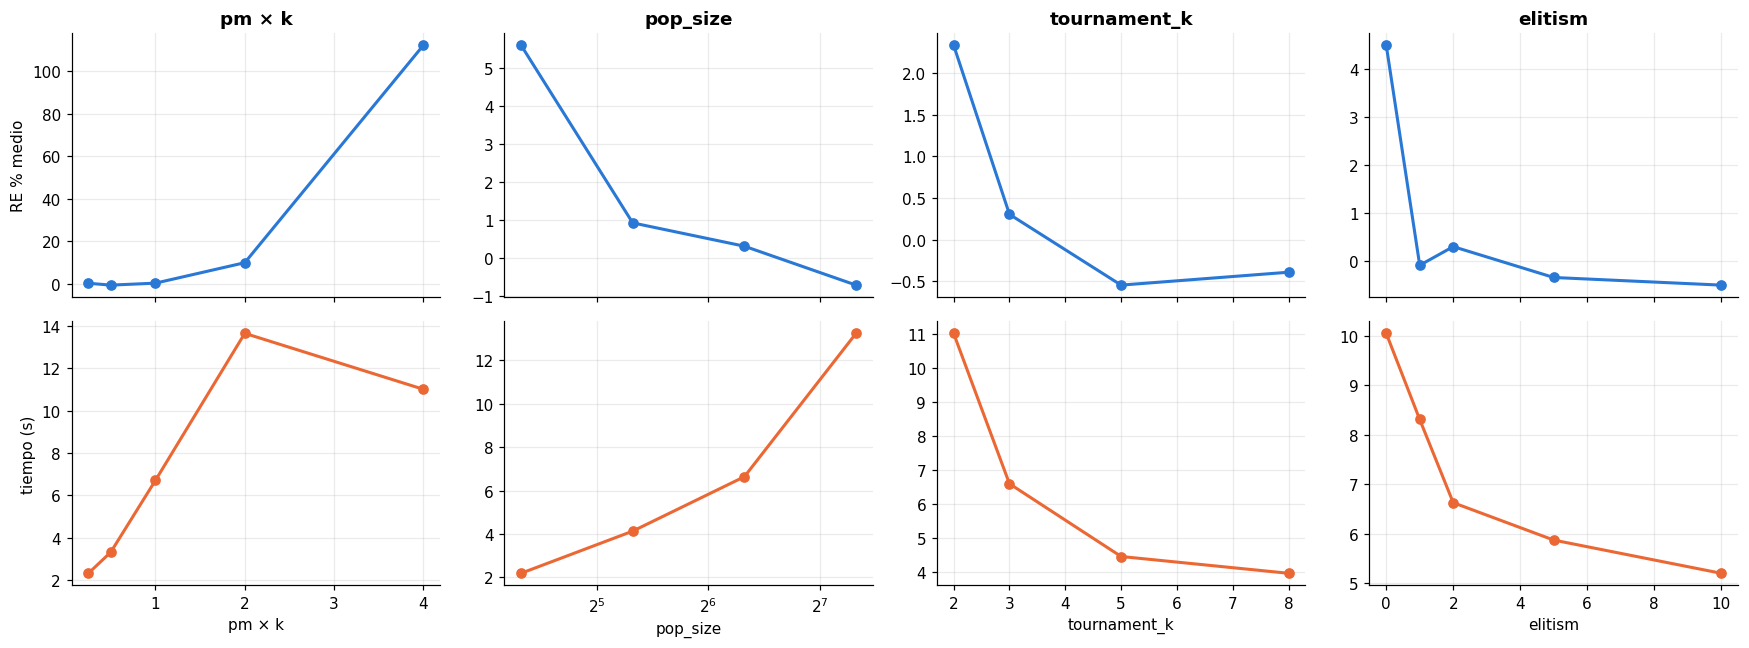

In [43]:
base_cfg = {"selection": "tournament", "crossover": "uniform", "mutation": "random_reset", "seeding": False}
grid = {
    "pm × k": [("pm", v) for v in [0.25, 0.5, 1.0, 2.0, 4.0]],
    "pop_size": [("pop_size", v) for v in [20, 40, 80, 160]],
    "tournament_k": [("tournament_k", v) for v in [2, 3, 5, 8]],
    "elitism": [("elitism", v) for v in [0, 1, 2, 5, 10]],
}
sens_configs = {}
for param, values in grid.items():
    for key, v in values:
        cfg = dict(base_cfg)
        if key == "pm":
            cfg["pm_factor"] = v
        else:
            cfg[key] = v
        sens_configs[f"{param}={v}"] = cfg


def run_sens(instance, query, fuel, seed, pm_factor=None, **cfg):
    if pm_factor is not None:
        cfg["pm"] = pm_factor / len(query)
    return run_ga(instance, query, fuel, seed, **cfg)


def sensitivity_runs():
    jobs = [(i, n, s) for i in bench_rows.index for n in sens_configs for s in (1, 2)]
    out = Parallel(n_jobs=N_JOBS)(delayed(run_sens)(instances[problemset.loc[i, "catalog_path"]], problemset.loc[i, "query"],
                                                    problemset.loc[i, "fuel_price"], s, **sens_configs[n]) for i, n, s in jobs)
    return pd.DataFrame([{"id": i, "config": n, **o} for (i, n, s), o in zip(jobs, out)])


sens = cached("runs_sensitivity", sensitivity_runs)
sens[["param", "value"]] = sens.config.str.split("=", expand=True)
sens["value"] = sens.value.astype(float)
sens["RE_%"] = 100 * (sens.cost - problemset.loc[sens.id, "best_known"].to_numpy()) / problemset.loc[sens.id, "best_known"].to_numpy()
sens.to_csv(RESULTS_DIR / "hyperparameter_sensitivity.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex="col")
for j, param in enumerate(grid):
    g = sens[sens.param == param].groupby("value").agg(RE=("RE_%", "mean"), t=("time", "mean"))
    axes[0, j].plot(g.index, g.RE, marker="o", color=PALETTE[0]); axes[0, j].set_title(param)
    axes[1, j].plot(g.index, g.t, marker="o", color=PALETTE[1]); axes[1, j].set_xlabel(param)
    if param == "pop_size":
        axes[0, j].set_xscale("log", base=2); axes[1, j].set_xscale("log", base=2)
axes[0, 0].set_ylabel("RE % medio"); axes[1, 0].set_ylabel("tiempo (s)")
plt.tight_layout()
save_fig(fig, "sensitivity")
plt.show()

**Lectura de la sensibilidad:**
- **`pm`**: es el parámetro más delicado. Entre 0.25/k y 1/k el AG funciona bien, pero con 2/k el RE sube a ≈ 10 % y con 4/k
  pasa de 100 %. Demasiada mutación convierte la búsqueda en un recorrido aleatorio.
- **Elitismo**: sin élites (0) el mejor individuo se puede perder y el RE sube a ≈ 4.5 %. Con 1 a 10 élites el RE queda cerca
  de 0 y la convergencia es más rápida.
- **`pop_size`**: más población da mejor calidad, pero el tiempo crece casi linealmente. 80 es un buen equilibrio.
- **`tournament_k`**: k = 5 mejora a k = 3 (más presión selectiva), pero k = 8 ya no mejora más.

Como estos valores se ajustaron sobre los mismos 24 problemas, recomendarlos como defaults sería *sobreajustar*.
Los dejamos documentados como recomendación.

### 17.1 Escalabilidad
¿Cómo crecen el tiempo y la calidad con el tamaño del problema? Comparamos también el costo teórico del método
exacto ($2^S$ subconjuntos) con el del AG (aproximadamente `pop_size × generaciones` evaluaciones, independiente de $S$).

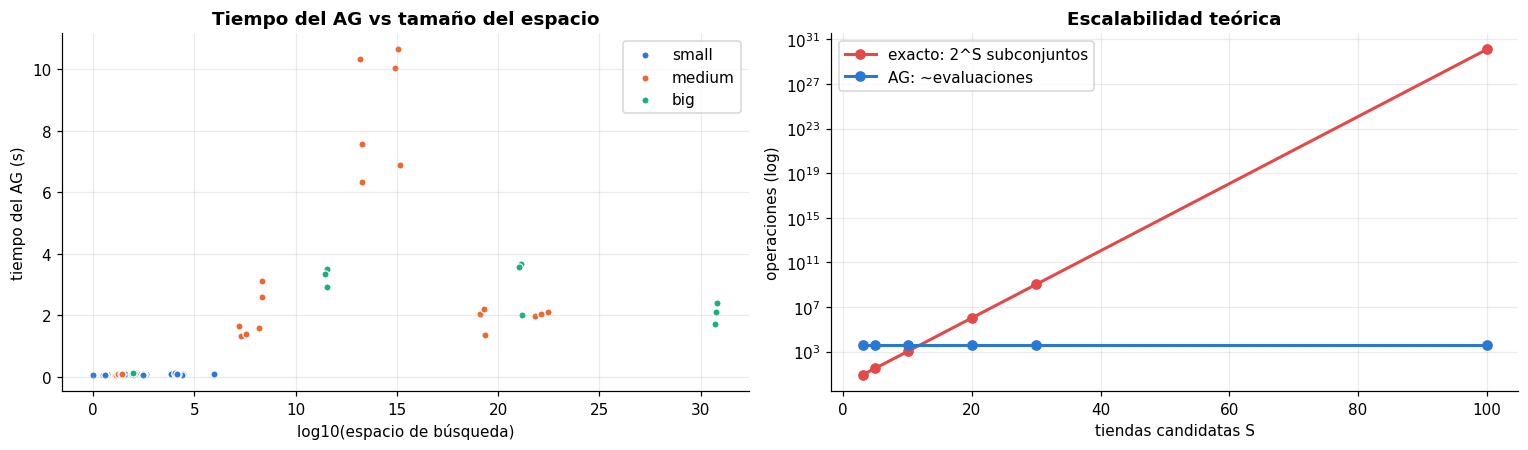

,time_seeded,generations,cache_hit_%
size,,,
big,2.12,50.00,47.69
medium,3.16,54.71,70.29
small,0.08,50.11,99.67


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for j, size in enumerate(["small", "medium", "big"]):
    m = results["size"] == size
    axes[0].scatter(results.loc[m, "log10_space"], results.loc[m, "time_seeded"], s=22, color=PALETTE[j], label=size,
                    edgecolor="white", linewidth=0.8)
axes[0].set_xlabel("log10(espacio de búsqueda)"); axes[0].set_ylabel("tiempo del AG (s)")
axes[0].set_title("Tiempo del AG vs tamaño del espacio"); axes[0].legend()

S = np.array([3, 5, 10, 20, 30, 100])
axes[1].semilogy(S, 2.0 ** S, marker="o", label="exacto: 2^S subconjuntos", color=PALETTE[7])
axes[1].semilogy(S, np.full(len(S), results.generations.mean() * 80), marker="o", label="AG: ~evaluaciones", color=PALETTE[0])
axes[1].set_xlabel("tiendas candidatas S"); axes[1].set_ylabel("operaciones (log)")
axes[1].set_title("Escalabilidad teórica"); axes[1].legend()
plt.tight_layout()
save_fig(fig, "scalability")
plt.show()
results.groupby("size")[["time_seeded", "generations", "cache_hit_%"]].mean()

## 18. Experimento: ¿conviene usar la GPU?
Para que la evaluación sea vectorizable en la GPU, la ruta sigue el **orden de los genes** (igual que las
soluciones de referencia) en lugar del TSP. Evaluamos poblaciones de $10^2$ a $10^6$ individuos con:
NumPy (CPU), PyTorch (CPU) y PyTorch (CUDA).

Este experimento existe porque la pregunta "¿por qué no usar la GPU?" es razonable, y la respuesta correcta no es una
opinión sino una medición.

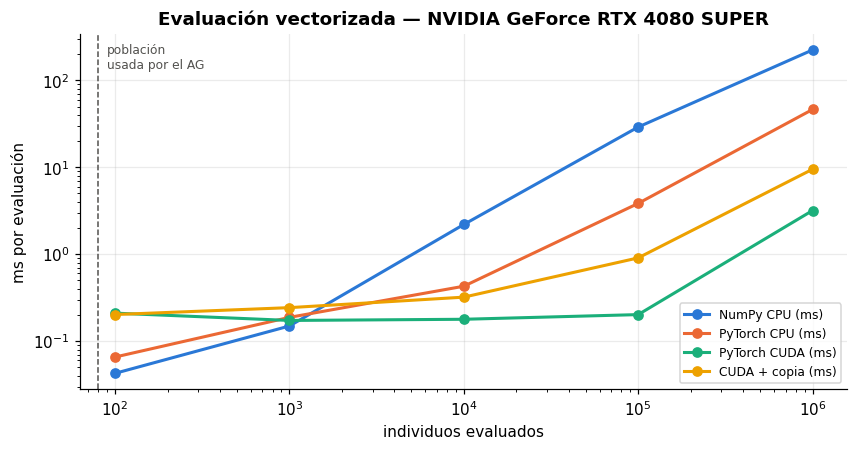

,NumPy CPU (ms),PyTorch CPU (ms),PyTorch CUDA (ms),CUDA + copia (ms)
población,,,,
100,0.04,0.07,0.21,0.20
1000,0.15,0.19,0.17,0.24
10000,2.20,0.43,0.18,0.32
100000,29.05,3.84,0.20,0.91
1000000,224.16,46.29,3.18,9.50


In [45]:
def batch_cost_numpy(population: np.ndarray, price: np.ndarray, D: np.ndarray,
                     fuel_price: float) -> np.ndarray:
    k = population.shape[1]
    products = price[population, np.arange(k)].sum(axis=1)
    points = np.pad(population + 1, ((0, 0), (1, 1)))            # home ... home
    distance = D[points[:, :-1], points[:, 1:]].sum(axis=1)
    return products + fuel_price * distance


def batch_cost_torch(population, price, D, fuel_price: float):
    import torch
    k = population.shape[1]
    products = price[population, torch.arange(k, device=population.device)].sum(dim=1)
    points = torch.nn.functional.pad(population + 1, (1, 1))
    distance = D[points[:, :-1], points[:, 1:]].sum(dim=1)
    return products + fuel_price * distance


def bench_fn(fn, repeat=5, sync=None):
    fn()
    if sync: sync()
    t = time.perf_counter()
    for _ in range(repeat):
        fn()
    if sync: sync()
    return 1000 * (time.perf_counter() - t) / repeat


r_big = problemset[problemset.problem_cluster.str.startswith("big")].sort_values("k").iloc[-1]
P_g = ShoppingProblem(instances[r_big.catalog_path], r_big.query, r_big.fuel_price)
price_np = np.where(np.isinf(P_g.price), 1e9, P_g.price)
gpu_rows = []
for n in [10**2, 10**3, 10**4, 10**5, 10**6]:
    pop_np = init_random(P_g, 1000, rng)[rng.integers(0, 1000, n)]
    rec = {"población": n, "NumPy CPU (ms)": bench_fn(lambda: batch_cost_numpy(pop_np, price_np, P_g.instance.D, P_g.fuel_price))}
    if torch is not None:
        for dev in ["cpu"] + (["cuda"] if GPU else []):
            pt, pr, dt = (torch.as_tensor(x, device=dev) for x in (pop_np, price_np, P_g.instance.D))
            sync = torch.cuda.synchronize if dev == "cuda" else None
            rec[f"PyTorch {dev.upper()} (ms)"] = bench_fn(lambda: batch_cost_torch(pt, pr, dt, P_g.fuel_price), sync=sync)
            if dev == "cuda":
                rec["CUDA + copia (ms)"] = bench_fn(
                    lambda: batch_cost_torch(torch.as_tensor(pop_np, device="cuda"), pr, dt, P_g.fuel_price).cpu(), sync=sync)
    gpu_rows.append(rec)
gpu_df = pd.DataFrame(gpu_rows).set_index("población")
gpu_df.to_csv(RESULTS_DIR / "cpu_vs_gpu.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
for j, col in enumerate(gpu_df.columns):
    ax.loglog(gpu_df.index, gpu_df[col], marker="o", label=col, color=PALETTE[j])
ax.axvline(80, color="#52514e", ls="--", lw=1)
ax.text(90, ax.get_ylim()[1] * 0.4, "población\nusada por el AG", fontsize=8, color="#52514e")
ax.set_xlabel("individuos evaluados"); ax.set_ylabel("ms por evaluación")
ax.set_title(f"Evaluación vectorizada — {GPU or 'CPU only'}"); ax.legend(fontsize=8)
save_fig(fig, "cpu_vs_gpu")
plt.show()
gpu_df

**Conclusión del experimento:**
- Con **80 individuos** (lo que usa el AG), NumPy en CPU es el más rápido: lanzar trabajo a la GPU cuesta más que el cálculo.
- A partir de **~10⁴ individuos** la GPU gana. Con **10⁶**, CUDA es ~80× más rápido que NumPy, o ~20–25× contando la copia de datos.
- Aun así, el cuello de botella real del AG es el **decodificador TSP** (programación dinámica, diccionarios), que no se
  vectoriza. Por eso se paraleliza *entre problemas* en el CPU.
- **Cuándo valdría la pena:** un AG "masivo" que evolucione cientos de miles de individuos, o todos los problemas a la
  vez, como tensores en la GPU. Queda como mejora futura.

## 19. Diagrama de flujo de datos
El resumen de todo lo anterior en una imagen: qué entra, qué se transforma y qué sale. Es la vista que conviene tener en
la cabeza antes de leer el código del paquete `src/`.

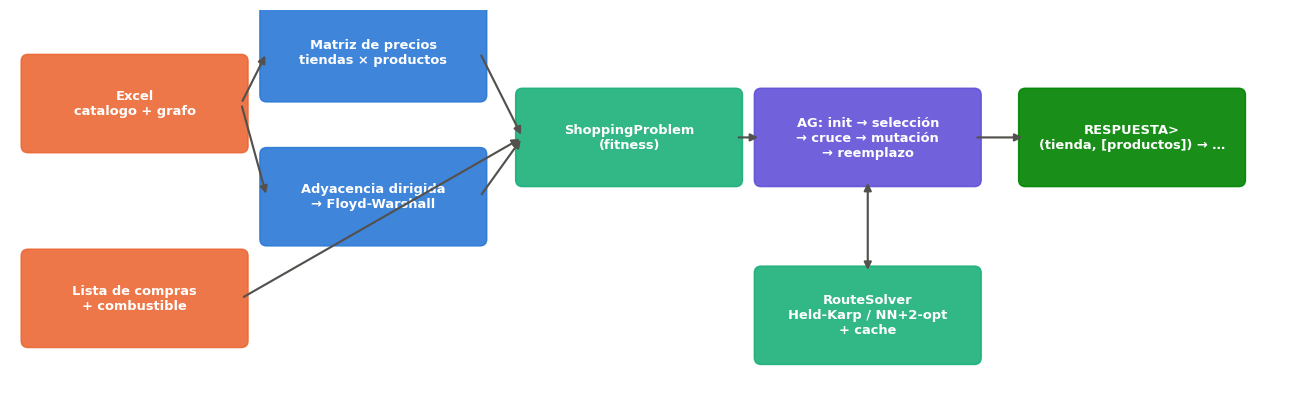

In [46]:
fig, ax = plt.subplots(figsize=(15, 4.6))
ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, 4.6)
boxes = {
    "xlsx": (0.2, 3.0, "Excel\ncatalogo + grafo", PALETTE[1]),
    "price": (3.0, 3.6, "Matriz de precios\ntiendas × productos", PALETTE[0]),
    "dist": (3.0, 1.9, "Adyacencia dirigida\n→ Floyd-Warshall", PALETTE[0]),
    "query": (0.2, 0.7, "Lista de compras\n+ combustible", PALETTE[1]),
    "problem": (6.0, 2.6, "ShoppingProblem\n(fitness)", PALETTE[2]),
    "ga": (8.8, 2.6, "AG: init → selección\n→ cruce → mutación\n→ reemplazo", PALETTE[6]),
    "tsp": (8.8, 0.5, "RouteSolver\nHeld-Karp / NN+2-opt\n+ cache", PALETTE[2]),
    "out": (11.9, 2.6, "RESPUESTA>\n(tienda, [productos]) → …", PALETTE[5]),
}
for x, y, text, color in boxes.values():
    ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), 2.5, 1.0, boxstyle="round,pad=0.08", color=color, alpha=0.9))
    ax.text(x + 1.25, y + 0.5, text, ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
arrow = dict(arrowstyle="-|>", color="#52514e", lw=1.4)
for a, b in [("xlsx", "price"), ("xlsx", "dist"), ("price", "problem"), ("dist", "problem"), ("query", "problem"),
             ("problem", "ga"), ("ga", "out")]:
    xa, ya = boxes[a][0] + 2.5, boxes[a][1] + 0.5
    xb, yb = boxes[b][0], boxes[b][1] + 0.5
    ax.annotate("", xy=(xb, yb), xytext=(xa, ya), arrowprops=arrow)
ax.annotate("", xy=(10.05, 1.5), xytext=(10.05, 2.6), arrowprops=dict(arrowstyle="<|-|>", color="#52514e", lw=1.4))
save_fig(fig, "dataflow")
plt.show()

## 20. Riesgos, limitaciones, mejoras y conclusiones

### Riesgos y limitaciones
- **El precio domina el costo.** Con estos datos el transporte pesa poco, así que la heurística "más barato" ya está
  cerca del óptimo. El AG aporta más cuando el combustible es caro o los precios se parecen (cluster `same_price`).
- **Distancias casi nulas en `big`.** El 97 % de los pares queda a distancia 0, así que ese cluster no pone a prueba
  la parte de rutas.
- **Sin garantía de optimalidad.** En problemas grandes no conocemos el óptimo real; solo podemos compararnos con las referencias.
- **Convergencia prematura.** La mutación de consolidación sin seeding reduce la diversidad demasiado rápido en
  problemas grandes (se ve en el benchmark).
- **Ruleta con costos similares.** Casi no ejerce presión selectiva (sección 11.2).
- **TSP heurístico con más de 9 tiendas.** NN + 2-opt no siempre es óptimo; en la práctica las rutas buenas visitan pocas tiendas.
- **Modelo de datos.** Supone stock infinito, una unidad por producto y un grafo dirigido conectado.

### Oportunidades de mejora
- AG **híbrido/memético**: búsqueda local (mover cada producto a su mejor tienda) sobre el mejor individuo.
- Parámetros **adaptativos** (pm que sube si la diversidad cae) o modelo de **islas** distribuido entre núcleos.
- Optimización **multiobjetivo** (NSGA-II): costo vs tiempo/distancia.
- Cantidades por producto, horarios de tiendas, ofertas tipo 2×1.
- Paralelizar la evaluación dentro de una ejecución (hoy se paraleliza *entre* problemas).

### Rendimiento y escalabilidad
El AG evalúa ~`pop_size × generaciones` cromosomas sin importar el tamaño del espacio de búsqueda, y la caché de
rutas evita recalcular conjuntos repetidos (≈ 99 % de aciertos en small y ≈ 70 % en medium). Un problema pequeño se
resuelve en ~0.1 s y uno mediano en ~3 s, y las 272 corridas de la validación toman ~25 s en paralelo usando todos
los núcleos. El método exacto crece como $2^S$ y deja de ser viable alrededor de 25–30 tiendas.

### Conclusiones
1. El modelo de costo se validó **504/504** contra las referencias, lo que reveló que el grafo es **dirigido**.
2. Separar **qué comprar** (genes) de **en qué orden ir** (heurística TSP) produce cromosomas siempre válidos y
   un espacio de búsqueda mucho menor.
3. El AG alcanza el **óptimo exacto en 100/100 problemas pequeños**, **iguala o supera a la mejor referencia en los
   136 problemas** (hit rate 100 %) y **la mejora en 30**, con un ahorro acumulado de 2,286.
4. **Torneo + reinicio aleatorio** es la combinación más robusta sin seeding. La mutación de consolidación causa
   convergencia prematura, y el seeding con greedy acelera la convergencia y garantiza no ser peor que ellos.
5. La GPU solo compensa desde ~10⁴ individuos. Con la población del AG (80), el CPU es más rápido, y el paralelismo
   útil está *entre* problemas.

## 21. Manual de usuario

**Instalación**
```bash
git clone <url-del-repo> && cd CompraGenetica
python -m venv .venv && .venv\Scripts\activate      # Windows  (Linux/Mac: source .venv/bin/activate)
pip install -e ".[notebook,dev]"
```

**Desde la línea de comandos**
```bash
compra-genetica --catalog data/in/small-3s-4p-f1_10-q1_4-random_catalog.xlsx \
                --products "Purificadores de aire,Aceite de girasol,Pasta de dientes,Alfombras" --fuel 1
```
(o `python -m compra_genetica ...` sin instalar el comando). Opciones: `--pop-size --generations --pc --pm --selection {tournament,roulette,rank}
--crossover {one_point,two_point,uniform} --mutation {random_reset,consolidate} --elitism --patience --seed --verbose`

**Desde Python**
```python
from compra_genetica import load_instance, ShoppingProblem, GeneticShoppingOptimizer
problem = ShoppingProblem(load_instance("mi_catalogo.xlsx"), ["Arroz", "Aceite"], fuel_price=5)
print(GeneticShoppingOptimizer(problem, selection="rank", seed=1).run().answer)
```

**Formato del Excel de entrada:** hoja 1 `store | product | price`, hoja 2 `edge 1 | edge 2 | distance`.
La casa debe llamarse `Casa`.

**Resultados guardados:** por defecto el notebook carga los experimentos pesados desde `results/`, así que corre en
segundos. Con `RECOMPUTE = True` (o `python tools/build_notebooks.py --recompute`) se recalcula todo.

**Tests:** `pytest -q` · **Regenerar los notebooks:** `python tools/build_notebooks.py`